STEP_1,2,3 already done

1.Import libraries

In [18]:

# ============================================================
# CUSTOMER FEEDBACK ANALYSIS USING NLP AND DEEP LEARNING
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

# 1. Data Manipulation
import pandas as pd
import numpy as np

# 2. Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 3. NLP Libraries
import re
import string
import nltk

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

# 4. Deep Learning - TensorFlow and Keras
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SimpleRNN,
    LSTM,
    GRU,
    Dense,
    Dropout,
    Bidirectional,
    SpatialDropout1D
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from tensorflow.keras.optimizers import Adam

# 5. Machine Learning - Dataset Preparation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 6. Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 7. Reproducibility
import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 8. Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

# 9. Download NLTK Resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# 10. Verify Deep Learning Architectures
print("TensorFlow Version:", tf.__version__)

print("\nDeep Learning Architectures Imported Successfully:")
print("1. SimpleRNN")
print("2. LSTM")
print("3. GRU")

print("\nAll Required Libraries Imported Successfully!")


TensorFlow Version: 2.21.0

Deep Learning Architectures Imported Successfully:
1. SimpleRNN
2. LSTM
3. GRU

All Required Libraries Imported Successfully!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


step_2

In [19]:

# ============================================================
# CUSTOMER FEEDBACK ANALYSIS USING NLP AND DEEP LEARNING
# STEP 2: DATASET LOADING AND INITIAL INSPECTION
# ============================================================

# Import required libraries
import pandas as pd
import numpy as np
from google.colab import files
import io

# 1. Upload Existing Dataset
print("Upload your Customer Feedback Dataset")
uploaded = files.upload()

# 2. Load Dataset
file_name = next(iter(uploaded.keys()))

if file_name.lower().endswith(".csv"):
    df = pd.read_csv(io.BytesIO(uploaded[file_name]))
elif file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(io.BytesIO(uploaded[file_name]))
else:
    raise ValueError("Please upload a CSV or Excel dataset.")

print("\nDataset Loaded Successfully!")
print("File Name:", file_name)

# 3. Display First Five Records
print("\n========== FIRST FIVE RECORDS ==========")
display(df.head())

# 4. Display Last Five Records
print("\n========== LAST FIVE RECORDS ==========")
display(df.tail())

# 5. Dataset Dimensions
print("\n========== DATASET DIMENSIONS ==========")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Dataset Shape:", df.shape)

# 6. Column Names
print("\n========== COLUMN NAMES ==========")
print(df.columns.tolist())

# 7. Dataset Information
print("\n========== DATASET INFORMATION ==========")
df.info()

# 8. Statistical Summary
print("\n========== STATISTICAL SUMMARY ==========")
display(df.describe(include="all").T)

# 9. Unique Values in Each Column
print("\n========== UNIQUE VALUES ==========")

for column in df.columns:
    print(f"\nColumn: {column}")
    print("Unique Values:", df[column].nunique())

    if df[column].nunique() <= 20:
        print("Values:", df[column].unique())

# 10. Final Dataset Loading Summary
print("\n========== FINAL SUMMARY ==========")
print("Dataset Name:", file_name)
print("Total Records:", len(df))
print("Total Features:", len(df.columns))
print("Memory Usage:", round(df.memory_usage(deep=True).sum() / 1024**2, 2), "MB")

print("\nStep 2 Completed Successfully!")


Upload your Customer Feedback Dataset


Saving review.csv to review (1).csv

Dataset Loaded Successfully!
File Name: review (1).csv

========== FIRST FIVE RECORDS ==========


,id,asins,brand,categories,colors,dateAdded,dateUpdated,dimension,ean,keys,...,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.userCity,reviews.userProvince,reviews.username,sizes,upc,weight
0,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I initially had trouble deciding between the p...,"Paperwhite voyage, no regrets!",NaN,NaN,Cristina M,NaN,NaN,205 grams
1,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,Allow me to preface this with a little history...,One Simply Could Not Ask For More,NaN,NaN,Ricky,NaN,NaN,205 grams
2,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,4.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I am enjoying it so far. Great for reading. Ha...,Great for those that just want an e-reader,NaN,NaN,Tedd Gardiner,NaN,NaN,205 grams
3,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I bought one of the first Paperwhites and have...,Love / Hate relationship,NaN,NaN,Dougal,NaN,NaN,205 grams
4,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I have to say upfront - I don't like coroporat...,I LOVE IT,NaN,NaN,Miljan David Tanic,NaN,NaN,205 grams



========== LAST FIVE RECORDS ==========


,id,asins,brand,categories,colors,dateAdded,dateUpdated,dimension,ean,keys,...,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.userCity,reviews.userProvince,reviews.username,sizes,upc,weight
1592,AVpfo9ukilAPnD_xfhuj,B00NO8JJZW,Amazon,"Amazon Devices & Accessories,Amazon Device Acc...",NaN,2016-04-02T14:40:43Z,2017-08-13T08:28:46Z,NaN,NaN,alexavoiceremoteforamazonfiretvfiretvstick/b00...,...,3.0,https://www.amazon.com/Alexa-Voice-Remote-Amaz...,This is not the same remote that I got for my ...,I would be disappointed with myself if i produ...,NaN,NaN,GregAmandawith4,NaN,NaN,4 ounces
1593,AVpfo9ukilAPnD_xfhuj,B00NO8JJZW,Amazon,"Amazon Devices & Accessories,Amazon Device Acc...",NaN,2016-04-02T14:40:43Z,2017-08-13T08:28:46Z,NaN,NaN,alexavoiceremoteforamazonfiretvfiretvstick/b00...,...,1.0,https://www.amazon.com/Alexa-Voice-Remote-Amaz...,I have had to change the batteries in this rem...,Battery draining remote!!!!,NaN,NaN,Amazon Customer,NaN,NaN,4 ounces
1594,AVpfo9ukilAPnD_xfhuj,B00NO8JJZW,Amazon,"Amazon Devices & Accessories,Amazon Device Acc...",NaN,2016-04-02T14:40:43Z,2017-08-13T08:28:46Z,NaN,NaN,alexavoiceremoteforamazonfiretvfiretvstick/b00...,...,1.0,https://www.amazon.com/Alexa-Voice-Remote-Amaz...,"Remote did not activate, nor did it connect to...",replacing an even worse remote. Waste of time,NaN,NaN,Amazon Customer,NaN,NaN,4 ounces
1595,AVpfo9ukilAPnD_xfhuj,B00NO8JJZW,Amazon,"Amazon Devices & Accessories,Amazon Device Acc...",NaN,2016-04-02T14:40:43Z,2017-08-13T08:28:46Z,NaN,NaN,alexavoiceremoteforamazonfiretvfiretvstick/b00...,...,3.0,https://www.amazon.com/Alexa-Voice-Remote-Amaz...,It does the job but is super over priced. I fe...,Overpriced,NaN,NaN,Meg Ashley,NaN,NaN,4 ounces
1596,AVpfo9ukilAPnD_xfhuj,B00NO8JJZW,Amazon,"Amazon Devices & Accessories,Amazon Device Acc...",NaN,2016-04-02T14:40:43Z,2017-08-13T08:28:46Z,NaN,NaN,alexavoiceremoteforamazonfiretvfiretvstick/b00...,...,1.0,https://www.amazon.com/Alexa-Voice-Remote-Amaz...,I ordered this item to replace the one that no...,I am sending all of this crap back to amazon a...,NaN,NaN,DIANE K,NaN,NaN,4 ounces



========== DATASET DIMENSIONS ==========
Total Rows: 1597
Total Columns: 27
Dataset Shape: (1597, 27)

========== COLUMN NAMES ==========
['id', 'asins', 'brand', 'categories', 'colors', 'dateAdded', 'dateUpdated', 'dimension', 'ean', 'keys', 'manufacturer', 'manufacturerNumber', 'name', 'prices', 'reviews.date', 'reviews.doRecommend', 'reviews.numHelpful', 'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.userCity', 'reviews.userProvince', 'reviews.username', 'sizes', 'upc', 'weight']

========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1597 entries, 0 to 1596
Data columns (total 27 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1597 non-null   object 
 1   asins                 1597 non-null   object 
 2   brand                 1597 non-null   object 
 3   categories            1597 non-null   object 
 4   colors         

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,1597,66,AVpfpK8KLJeJML43BCuD,542,NaN,NaN,NaN,NaN,NaN,NaN,NaN
asins,1597,54,B01BH83OOM,542,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,1597,2,Amazon,1585,NaN,NaN,NaN,NaN,NaN,NaN,NaN
categories,1597,19,"Amazon Devices,Home,Smart Home & Connected Liv...",542,NaN,NaN,NaN,NaN,NaN,NaN,NaN
colors,774,3,Black,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dateAdded,1597,50,2017-01-04T03:51:17Z,542,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dateUpdated,1597,42,2017-08-13T08:31:07Z,542,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dimension,565,2,4.8 in x 6.6 in x 3.2 in,542,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ean,898.0,NaN,NaN,NaN,844313463251.67041,3416443908.547778,841667000000.0,841667000000.0,841667000000.0,848719000000.0,848719000000.0
keys,1597,66,amazontapalexaenabledportablebluetoothspeaker/...,542,NaN,NaN,NaN,NaN,NaN,NaN,NaN



========== UNIQUE VALUES ==========

Column: id
Unique Values: 66

Column: asins
Unique Values: 54

Column: brand
Unique Values: 2
Values: ['Amazon' 'Moshi']

Column: categories
Unique Values: 19
Values: ['Amazon Devices,mazon.co.uk' 'Kindle Store,Amazon Devices,Electronics'
 'Categories,Amazon Devices,Streaming Media Players' 'Amazon Devices'
 'Categories,Amazon Devices,Electronics Features,Streaming Media Players,Consumer Electronics,See more Amazon Fire TV Digital HD Media Streamer (Late...'
 'Amazon Devices & Accessories,Amazon Device Accessories,Power Adapters & Cables,Kindle Store,Kindle E-Reader Accessories,Kindle Paperwhite Accessories'
 'Amazon Devices,Kindle Store' 'Electronics,Amazon Devices'
 'Amazon Devices,Kindle Accessories'
 'Amazon Devices,Electronics,Kindle Store'
 'Amazon Devices,Electronics,Kindle Store,Amazon Echo'
 'Amazon Devices,Kindle Store,Kindle Accessories'
 'Amazon Devices,Kindle Store,buy a kindle'
 'Amazon Devices,Home,Smart Home & Connected Living,Smart

step_3

In [20]:

# ============================================================
# CUSTOMER FEEDBACK ANALYSIS USING NLP AND DEEP LEARNING
# STEP 3: DATA QUALITY ASSESSMENT
# ============================================================

import pandas as pd
import numpy as np

# 1. Check Dataset Shape
print("=" * 60)
print("1. DATASET DIMENSIONS")
print("=" * 60)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# 2. Check Missing Values
print("\n" + "=" * 60)
print("2. MISSING VALUE ANALYSIS")
print("=" * 60)

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

display(missing_summary)

# 3. Check Duplicate Records
print("\n" + "=" * 60)
print("3. DUPLICATE RECORD ANALYSIS")
print("=" * 60)

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

# 4. Check Empty or Whitespace-Only Text Values
print("\n" + "=" * 60)
print("4. EMPTY TEXT VALUE ANALYSIS")
print("=" * 60)

object_columns = df.select_dtypes(include="object").columns

for column in object_columns:
    empty_count = df[column].apply(
        lambda x: isinstance(x, str) and x.strip() == ""
    ).sum()

    print(f"{column}: {empty_count} empty values")

# 5. Check Data Types
print("\n" + "=" * 60)
print("5. DATA TYPE ANALYSIS")
print("=" * 60)

print(df.dtypes)

# 6. Check Unique Values
print("\n" + "=" * 60)
print("6. UNIQUE VALUE ANALYSIS")
print("=" * 60)

for column in df.columns:
    print(f"\n{column}")
    print("Unique Values:", df[column].nunique())

# 7. Check Target / Sentiment Distribution
print("\n" + "=" * 60)
print("7. SENTIMENT LABEL DISTRIBUTION")
print("=" * 60)

# Update this column name after identifying your actual target column
# Example: sentiment, label, rating, review_score

possible_target_columns = [
    "sentiment", "label", "target", "review_sentiment"
]

target_column = next(
    (col for col in df.columns
     if col.lower() in possible_target_columns),
    None
)

if target_column is not None:
    print("Target Column:", target_column)
    print(df[target_column].value_counts(dropna=False))
else:
    print("Sentiment column not automatically identified.")
    print("Available columns:", df.columns.tolist())

# 8. Check Text Length (for text columns)
print("\n" + "=" * 60)
print("8. TEXT LENGTH ANALYSIS")
print("=" * 60)

# Update with your actual feedback text column if necessary
possible_text_columns = [
    "feedback", "review", "customer_feedback",
    "review_text", "text", "comment"
]

text_column = next(
    (col for col in df.columns
     if col.lower() in possible_text_columns),
    None
)

if text_column is not None:
    print("Text Column:", text_column)

    text_lengths = df[text_column].fillna("").astype(str).str.len()

    print("Average Text Length:", round(text_lengths.mean(), 2))
    print("Minimum Text Length:", text_lengths.min())
    print("Maximum Text Length:", text_lengths.max())
else:
    print("Feedback text column not automatically identified.")

# 9. Final Data Quality Report
print("\n" + "=" * 60)
print("9. FINAL DATA QUALITY REPORT")
print("=" * 60)

print("Total Records:", len(df))
print("Total Columns:", len(df.columns))
print("Total Missing Values:", df.isnull().sum().sum())
print("Total Duplicate Records:", df.duplicated().sum())

print("\nData Quality Assessment Completed Successfully!")


1. DATASET DIMENSIONS
Rows: 1597
Columns: 27

2. MISSING VALUE ANALYSIS


,Missing Count,Missing Percentage
id,0,0.000000
asins,0,0.000000
brand,0,0.000000
categories,0,0.000000
colors,823,51.534126
dateAdded,0,0.000000
dateUpdated,0,0.000000
dimension,1032,64.621165
ean,699,43.769568
keys,0,0.000000



3. DUPLICATE RECORD ANALYSIS
Total Duplicate Records: 0

4. EMPTY TEXT VALUE ANALYSIS
id: 0 empty values
asins: 0 empty values
brand: 0 empty values
categories: 0 empty values
colors: 0 empty values
dateAdded: 0 empty values
dateUpdated: 0 empty values
dimension: 0 empty values
keys: 0 empty values
manufacturer: 0 empty values
manufacturerNumber: 0 empty values
name: 0 empty values
prices: 0 empty values
reviews.date: 0 empty values
reviews.doRecommend: 0 empty values
reviews.sourceURLs: 0 empty values
reviews.text: 0 empty values
reviews.title: 0 empty values
reviews.username: 0 empty values
weight: 0 empty values

5. DATA TYPE ANALYSIS
id                       object
asins                    object
brand                    object
categories               object
colors                   object
dateAdded                object
dateUpdated              object
dimension                object
ean                     float64
keys                     object
manufacturer             object
m

step_4

In [21]:

# ============================================================
# CUSTOMER FEEDBACK ANALYSIS USING NLP AND DEEP LEARNING
# STEP 4: DATA CLEANING
# DATASET: AMAZON CUSTOMER PRODUCT REVIEWS
# ============================================================

import pandas as pd
import numpy as np
import re

# 1. Create a copy of the original dataset
df_clean = df.copy()

print("Original Dataset Shape:", df_clean.shape)

# 2. Define Actual Dataset Columns
text_column = "reviews.text"
rating_column = "reviews.rating"
title_column = "reviews.title"

# 3. Validate Required Columns
required_columns = [text_column, rating_column]

for column in required_columns:
    if column not in df_clean.columns:
        raise ValueError(f"Required column not found: {column}")

# 4. Remove Duplicate Records
duplicate_count = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates()

print("\nDuplicate Records Removed:", duplicate_count)

# 5. Handle Missing Customer Feedback
df_clean[text_column] = df_clean[text_column].astype("string").str.strip()

df_clean = df_clean.dropna(subset=[text_column])

df_clean = df_clean[
    df_clean[text_column].str.len() > 0
]

print("Missing and Empty Feedback Removed")

# 6. Handle Missing Ratings
df_clean[rating_column] = pd.to_numeric(
    df_clean[rating_column],
    errors="coerce"
)

df_clean = df_clean.dropna(subset=[rating_column])

# 7. Validate Rating Values
df_clean = df_clean[
    df_clean[rating_column].between(1, 5)
]

# 8. Normalize Feedback Text
df_clean[text_column] = (
    df_clean[text_column]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# 9. Clean Review Titles (Optional)
if title_column in df_clean.columns:
    df_clean[title_column] = (
        df_clean[title_column]
        .astype("string")
        .str.strip()
    )

# 10. Create Sentiment Labels from Ratings
def assign_sentiment(rating):

    if rating <= 2:
        return "Negative"

    elif rating == 3:
        return "Neutral"

    else:
        return "Positive"

df_clean["sentiment"] = df_clean[rating_column].apply(
    assign_sentiment
)

# 11. Display Sentiment Distribution
print("\nSentiment Distribution:")
print(df_clean["sentiment"].value_counts())

# 12. Check Missing Values
print("\nRemaining Missing Values:")
print(df_clean.isnull().sum())

# 13. Check Duplicate Records
print("\nRemaining Duplicate Records:")
print(df_clean.duplicated().sum())

# 14. Display Cleaned Dataset
print("\nCleaned Dataset Preview:")
display(
    df_clean[
        [text_column, rating_column, "sentiment"]
    ].head()
)

# 15. Final Cleaning Summary
print("\n" + "=" * 55)
print("DATA CLEANING COMPLETED SUCCESSFULLY")
print("=" * 55)

print("Original Records:", len(df))
print("Cleaned Records:", len(df_clean))
print("Removed Records:", len(df) - len(df_clean))
print("Final Dataset Shape:", df_clean.shape)

print("\nInput Feature:", text_column)
print("Rating Column:", rating_column)
print("Target Feature: sentiment")

print("\nSentiment Classes:")
print(df_clean["sentiment"].unique())


Original Dataset Shape: (1597, 27)

Duplicate Records Removed: 0
Missing and Empty Feedback Removed

Sentiment Distribution:
sentiment
Positive    977
Neutral     124
Negative     76
Name: count, dtype: int64

Remaining Missing Values:
id                         0
asins                      0
brand                      0
categories                 0
colors                   508
dateAdded                  0
dateUpdated                0
dimension                620
ean                      484
keys                       0
manufacturer             451
manufacturerNumber       479
name                       0
prices                     0
reviews.date             217
reviews.doRecommend      638
reviews.numHelpful       277
reviews.rating             0
reviews.sourceURLs         0
reviews.text               0
reviews.title              0
reviews.userCity        1177
reviews.userProvince    1177
reviews.username           0
sizes                   1177
upc                      484
weight    

,reviews.text,reviews.rating,sentiment
0,I initially had trouble deciding between the p...,5.0,Positive
1,Allow me to preface this with a little history...,5.0,Positive
2,I am enjoying it so far. Great for reading. Ha...,4.0,Positive
3,I bought one of the first Paperwhites and have...,5.0,Positive
4,I have to say upfront - I don't like coroporat...,5.0,Positive



DATA CLEANING COMPLETED SUCCESSFULLY
Original Records: 1597
Cleaned Records: 1177
Removed Records: 420
Final Dataset Shape: (1177, 28)

Input Feature: reviews.text
Rating Column: reviews.rating
Target Feature: sentiment

Sentiment Classes:
['Positive' 'Neutral' 'Negative']


In [22]:
# Display actual dataset column names

print("Available Columns:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Available Columns:
['id', 'asins', 'brand', 'categories', 'colors', 'dateAdded', 'dateUpdated', 'dimension', 'ean', 'keys', 'manufacturer', 'manufacturerNumber', 'name', 'prices', 'reviews.date', 'reviews.doRecommend', 'reviews.numHelpful', 'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.userCity', 'reviews.userProvince', 'reviews.username', 'sizes', 'upc', 'weight']

First 5 Records:


,id,asins,brand,categories,colors,dateAdded,dateUpdated,dimension,ean,keys,...,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.userCity,reviews.userProvince,reviews.username,sizes,upc,weight
0,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I initially had trouble deciding between the p...,"Paperwhite voyage, no regrets!",NaN,NaN,Cristina M,NaN,NaN,205 grams
1,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,Allow me to preface this with a little history...,One Simply Could Not Ask For More,NaN,NaN,Ricky,NaN,NaN,205 grams
2,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,4.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I am enjoying it so far. Great for reading. Ha...,Great for those that just want an e-reader,NaN,NaN,Tedd Gardiner,NaN,NaN,205 grams
3,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I bought one of the first Paperwhites and have...,Love / Hate relationship,NaN,NaN,Dougal,NaN,NaN,205 grams
4,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,5.0,https://www.amazon.com/Kindle-Paperwhite-High-...,I have to say upfront - I don't like coroporat...,I LOVE IT,NaN,NaN,Miljan David Tanic,NaN,NaN,205 grams


step_5

DATASET OVERVIEW
Dataset Shape: (1177, 28)

Columns: ['id', 'asins', 'brand', 'categories', 'colors', 'dateAdded', 'dateUpdated', 'dimension', 'ean', 'keys', 'manufacturer', 'manufacturerNumber', 'name', 'prices', 'reviews.date', 'reviews.doRecommend', 'reviews.numHelpful', 'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.userCity', 'reviews.userProvince', 'reviews.username', 'sizes', 'upc', 'weight', 'sentiment']


,id,asins,brand,categories,colors,dateAdded,dateUpdated,dimension,ean,keys,...,reviews.sourceURLs,reviews.text,reviews.title,reviews.userCity,reviews.userProvince,reviews.username,sizes,upc,weight,sentiment
0,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,https://www.amazon.com/Kindle-Paperwhite-High-...,I initially had trouble deciding between the p...,"Paperwhite voyage, no regrets!",NaN,NaN,Cristina M,NaN,NaN,205 grams,Positive
1,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,https://www.amazon.com/Kindle-Paperwhite-High-...,Allow me to preface this with a little history...,One Simply Could Not Ask For More,NaN,NaN,Ricky,NaN,NaN,205 grams,Positive
2,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,https://www.amazon.com/Kindle-Paperwhite-High-...,I am enjoying it so far. Great for reading. Ha...,Great for those that just want an e-reader,NaN,NaN,Tedd Gardiner,NaN,NaN,205 grams,Positive
3,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,https://www.amazon.com/Kindle-Paperwhite-High-...,I bought one of the first Paperwhites and have...,Love / Hate relationship,NaN,NaN,Dougal,NaN,NaN,205 grams,Positive
4,AVpe7AsMilAPnD_xQ78G,B00QJDU3KY,Amazon,"Amazon Devices,mazon.co.uk",NaN,2016-03-08T20:21:53Z,2017-07-18T23:52:58Z,169 mm x 117 mm x 9.1 mm,NaN,kindlepaperwhite/b00qjdu3ky,...,https://www.amazon.com/Kindle-Paperwhite-High-...,I have to say upfront - I don't like coroporat...,I LOVE IT,NaN,NaN,Miljan David Tanic,NaN,NaN,205 grams,Positive



MISSING VALUES
colors                   508
dimension                620
ean                      484
manufacturer             451
manufacturerNumber       479
reviews.date             217
reviews.doRecommend      638
reviews.numHelpful       277
reviews.userCity        1177
reviews.userProvince    1177
sizes                   1177
upc                      484
weight                   525
dtype: int64

SENTIMENT DISTRIBUTION
sentiment
Positive    977
Neutral     124
Negative     76
Name: count, dtype: int64


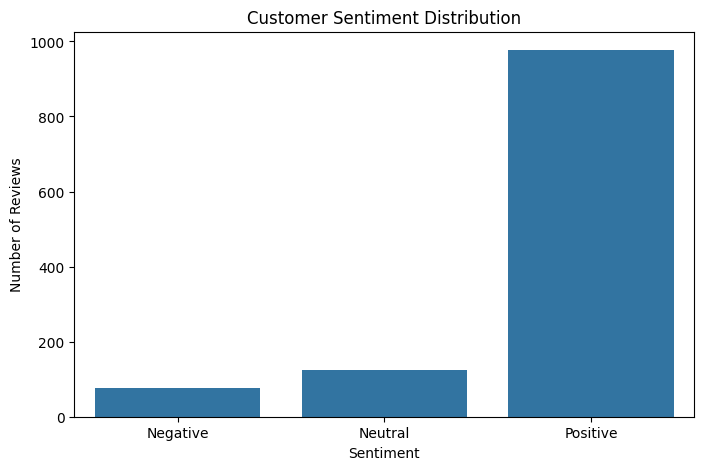


Sentiment Percentage:
sentiment
Positive    83.01
Neutral     10.54
Negative     6.46
Name: proportion, dtype: float64


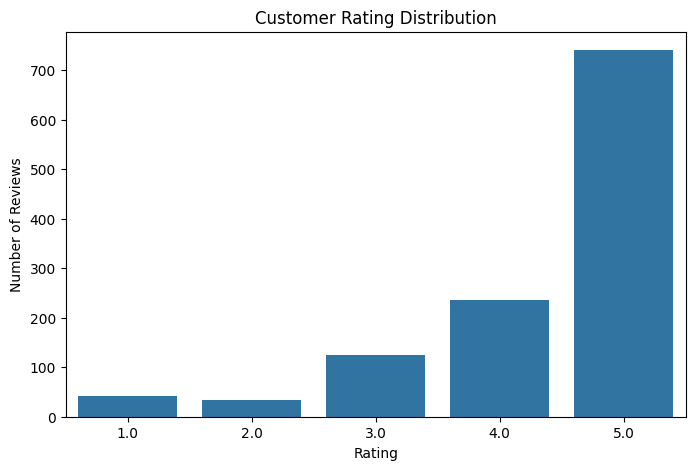


REVIEW LENGTH STATISTICS
       review_length   word_count
count    1177.000000  1177.000000
mean      735.956669   134.911640
std      1284.391365   229.622425
min         3.000000     1.000000
25%       115.000000    22.000000
50%       280.000000    54.000000
75%      1527.000000   270.000000
max     19739.000000  3601.000000


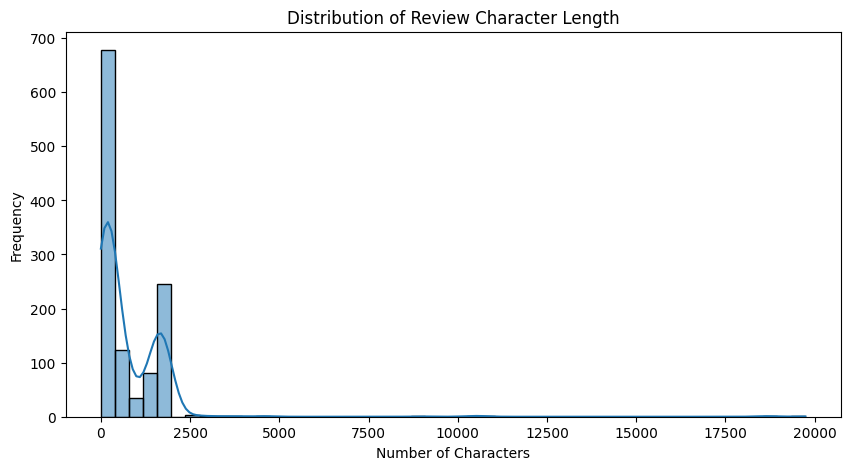

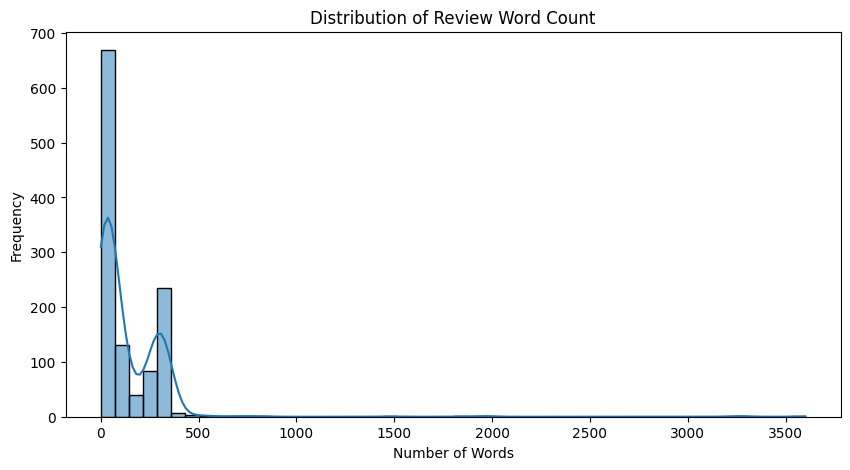

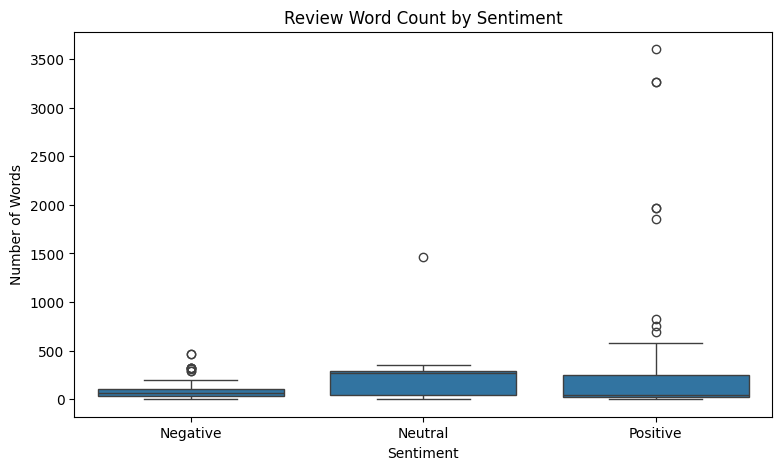


MOST FREQUENT WORDS IN CUSTOMER REVIEWS


,Word,Frequency
0,the,8690
1,i,5386
2,to,4701
3,and,4171
4,a,3856
5,it,3422
6,is,2741
7,of,2305
8,for,2116
9,you,1958


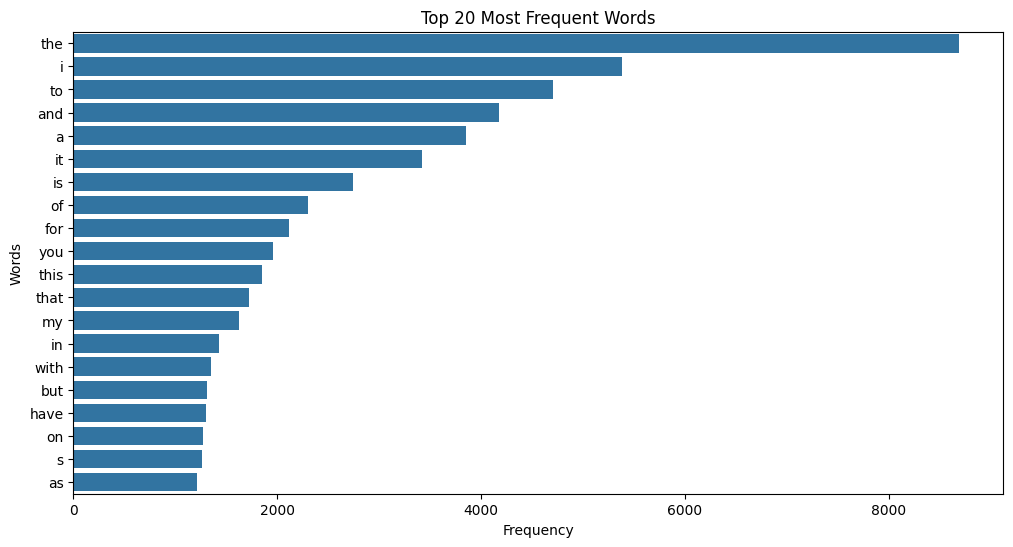


Top 10 Words in Positive Reviews:
  Word  Frequency
0  the       7332
1    i       4001
2   to       3789
3  and       3501
4    a       3049
5   it       2795
6   is       2381
7   of       1860
8  for       1751
9  you       1748

Top 10 Words in Negative Reviews:
   Word  Frequency
0   the        421
1     i        272
2    it        258
3    to        195
4     a        193
5   and        172
6    of        129
7    is        117
8   for        100
9  this         91

Top 10 Words in Neutral Reviews:
   Word  Frequency
0     i       1113
1   the        937
2    to        717
3     a        614
4   and        498
5     s        395
6    it        369
7    of        316
8  they        301
9    as        300

SAMPLE CUSTOMER REVIEWS

POSITIVE REVIEWS


,reviews.text,reviews.rating
0,I initially had trouble deciding between the p...,5.0
1,Allow me to preface this with a little history...,5.0
2,I am enjoying it so far. Great for reading. Ha...,4.0



NEGATIVE REVIEWS


,reviews.text,reviews.rating
108,"After 15 months, my 500+ tablet is no longer u...",1.0
170,"This is a great controller for our Fire TV, I ...",2.0
181,"This is a great controller for our Fire TV, I ...",2.0



NEUTRAL REVIEWS


,reviews.text,reviews.rating
51,The Kindle is my first e-ink reader. I own an ...,3.0
52,The Kindle is my first e-ink reader. I own an ...,3.0
97,Like a previous reviewer mentioned it is fabri...,3.0



EDA SUMMARY
Total Reviews: 1177
Total Sentiment Classes: 3
Average Review Length: 735.96
Average Word Count: 134.91
Minimum Word Count: 1
Maximum Word Count: 3601

Sentiment Counts:
sentiment
Positive    977
Neutral     124
Negative     76
Name: count, dtype: int64

EDA COMPLETED SUCCESSFULLY!


In [23]:

# ============================================================
# STEP 5: EXPLORATORY DATA ANALYSIS (EDA)
# CUSTOMER FEEDBACK ANALYSIS USING NLP AND DEEP LEARNING
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

# ------------------------------------------------------------
# 1. CHECK DATASET
# ------------------------------------------------------------

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("Dataset Shape:", df_clean.shape)
print("\nColumns:", df_clean.columns.tolist())

display(df_clean.head())

# ------------------------------------------------------------
# 2. CHECK MISSING VALUES
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MISSING VALUES")
print("=" * 60)

missing_values = df_clean.isnull().sum()

print(missing_values[missing_values > 0])

# ------------------------------------------------------------
# 3. SENTIMENT DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SENTIMENT DISTRIBUTION")
print("=" * 60)

sentiment_counts = df_clean["sentiment"].value_counts()

print(sentiment_counts)

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df_clean,
    x="sentiment",
    order=["Negative", "Neutral", "Positive"]
)
plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

# Sentiment percentage

sentiment_percentage = (
    df_clean["sentiment"].value_counts(normalize=True) * 100
)

print("\nSentiment Percentage:")
print(sentiment_percentage.round(2))

# ------------------------------------------------------------
# 4. RATING DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="reviews.rating",
    order=sorted(df_clean["reviews.rating"].dropna().unique())
)

plt.title("Customer Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

# ------------------------------------------------------------
# 5. REVIEW TEXT LENGTH
# ------------------------------------------------------------

df_clean["review_length"] = df_clean["reviews.text"].astype(str).apply(len)

df_clean["word_count"] = (
    df_clean["reviews.text"].astype(str).apply(lambda text: len(text.split()))
)

print("\n" + "=" * 60)
print("REVIEW LENGTH STATISTICS")
print("=" * 60)

print(df_clean[["review_length", "word_count"]].describe())

# Review character length distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="review_length",
    bins=50,
    kde=True
)

plt.title("Distribution of Review Character Length")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.show()

# Review word count distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="word_count",
    bins=50,
    kde=True
)

plt.title("Distribution of Review Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

# ------------------------------------------------------------
# 6. REVIEW LENGTH BY SENTIMENT
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="sentiment",
    y="word_count",
    order=["Negative", "Neutral", "Positive"]
)

plt.title("Review Word Count by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.show()

# ------------------------------------------------------------
# 7. MOST FREQUENT WORDS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MOST FREQUENT WORDS IN CUSTOMER REVIEWS")
print("=" * 60)

# Basic token extraction for EDA only.
# This does not modify the original review text.

all_words = []

for review in df_clean["reviews.text"].dropna():
    words = re.findall(r"\b[a-zA-Z]+\b", str(review).lower())
    all_words.extend(words)

word_counts = Counter(all_words)

most_common_words = word_counts.most_common(20)

word_frequency_df = pd.DataFrame(
    most_common_words,
    columns=["Word", "Frequency"]
)

display(word_frequency_df)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=word_frequency_df,
    x="Frequency",
    y="Word"
)

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.show()

# ------------------------------------------------------------
# 8. MOST FREQUENT WORDS BY SENTIMENT
# ------------------------------------------------------------

for sentiment_name in ["Positive", "Negative", "Neutral"]:

    sentiment_reviews = df_clean.loc[
        df_clean["sentiment"] == sentiment_name,
        "reviews.text"
    ].dropna()

    sentiment_words = []

    for review in sentiment_reviews:
        words = re.findall(r"\b[a-zA-Z]+\b", str(review).lower())
        sentiment_words.extend(words)

    top_words = Counter(sentiment_words).most_common(10)

    print(f"\nTop 10 Words in {sentiment_name} Reviews:")
    print(pd.DataFrame(top_words, columns=["Word", "Frequency"]))

# ------------------------------------------------------------
# 9. SAMPLE REVIEWS FROM EACH SENTIMENT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SAMPLE CUSTOMER REVIEWS")
print("=" * 60)

for sentiment_name in ["Positive", "Negative", "Neutral"]:

    print(f"\n{sentiment_name.upper()} REVIEWS")

    sample_reviews = df_clean.loc[
        df_clean["sentiment"] == sentiment_name,
        ["reviews.text", "reviews.rating"]
    ].head(3)

    display(sample_reviews)

# ------------------------------------------------------------
# 10. FINAL EDA SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("EDA SUMMARY")
print("=" * 60)

print("Total Reviews:", len(df_clean))
print("Total Sentiment Classes:", df_clean["sentiment"].nunique())
print("Average Review Length:", round(df_clean["review_length"].mean(), 2))
print("Average Word Count:", round(df_clean["word_count"].mean(), 2))
print("Minimum Word Count:", df_clean["word_count"].min())
print("Maximum Word Count:", df_clean["word_count"].max())

print("\nSentiment Counts:")
print(df_clean["sentiment"].value_counts())

print("\nEDA COMPLETED SUCCESSFULLY!")


step_6

In [24]:

# ============================================================
# STEP 6: TEXT PREPROCESSING AND NLP DATA PREPARATION
# PROJECT: CUSTOMER FEEDBACK ANALYSIS USING DEEP LEARNING
# ============================================================

import pandas as pd
import numpy as np
import re
import html

# ------------------------------------------------------------
# 1. CREATE A COPY OF THE DATASET
# ------------------------------------------------------------

df_step6 = df.copy()

print("Original Dataset Shape:", df_step6.shape)

# ------------------------------------------------------------
# 2. DEFINE REQUIRED COLUMNS
# ------------------------------------------------------------

text_col = "reviews.text"
rating_col = "reviews.rating"

print("\nAvailable Required Columns:")
print("Review Text:", text_col in df_step6.columns)
print("Review Rating:", rating_col in df_step6.columns)

# Verify required columns
if text_col not in df_step6.columns:
    raise KeyError(f"Column '{text_col}' not found in dataset.")

if rating_col not in df_step6.columns:
    raise KeyError(f"Column '{rating_col}' not found in dataset.")

# ------------------------------------------------------------
# 3. CHECK MISSING VALUES
# ------------------------------------------------------------

print("\nMissing Values Before Cleaning:")

print(df_step6[[text_col, rating_col]].isnull().sum())

# ------------------------------------------------------------
# 4. REMOVE MISSING REVIEW TEXT AND RATINGS
# ------------------------------------------------------------

df_step6 = df_step6.dropna(
    subset=[text_col, rating_col]
).copy()

# ------------------------------------------------------------
# 5. CONVERT REVIEW TEXT INTO STRING FORMAT
# ------------------------------------------------------------

df_step6[text_col] = df_step6[text_col].astype(str)

# Remove empty and whitespace-only reviews
df_step6 = df_step6[
    df_step6[text_col].str.strip().ne("")
].copy()

# ------------------------------------------------------------
# 6. CONVERT RATINGS INTO NUMERIC FORMAT
# ------------------------------------------------------------

df_step6[rating_col] = pd.to_numeric(
    df_step6[rating_col],
    errors="coerce"
)

df_step6 = df_step6.dropna(
    subset=[rating_col]
).copy()

# Keep valid ratings between 1 and 5
df_step6 = df_step6[
    df_step6[rating_col].between(1, 5)
].copy()

# ------------------------------------------------------------
# 7. REMOVE EXACT DUPLICATE REVIEW-RATING PAIRS
# ------------------------------------------------------------

df_step6 = df_step6.drop_duplicates(
    subset=[text_col, rating_col]
).copy()

print("\nDataset Shape After Initial Cleaning:")
print(df_step6.shape)

# ------------------------------------------------------------
# 8. PRESERVE ORIGINAL REVIEW TEXT
# ------------------------------------------------------------

df_step6["original_review"] = df_step6[text_col].copy()

# ------------------------------------------------------------
# 9. DEFINE TEXT CLEANING FUNCTION
# ------------------------------------------------------------

def clean_review(text):

    # Convert to lowercase
    text = text.lower()

    # Decode HTML entities
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove email addresses
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b",
        " ",
        text
    )

    # Remove special characters but preserve apostrophes
    text = re.sub(r"[^a-z0-9'\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

# ------------------------------------------------------------
# 10. APPLY TEXT PREPROCESSING
# ------------------------------------------------------------

df_step6["cleaned_review"] = df_step6[
    "original_review"
].apply(clean_review)

# ------------------------------------------------------------
# 11. REMOVE EMPTY CLEANED REVIEWS
# ------------------------------------------------------------

df_step6 = df_step6[
    df_step6["cleaned_review"].str.strip().ne("")
].copy()

# ------------------------------------------------------------
# 12. CREATE SENTIMENT LABELS USING RATINGS
# ------------------------------------------------------------

def get_sentiment(rating):

    if rating <= 2:
        return "Negative"

    elif rating == 3:
        return "Neutral"

    else:
        return "Positive"

df_step6["sentiment"] = df_step6[
    rating_col
].apply(get_sentiment)

# ------------------------------------------------------------
# 13. ENCODE SENTIMENT LABELS
# ------------------------------------------------------------

sentiment_mapping = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

df_step6["sentiment_label"] = df_step6[
    "sentiment"
].map(sentiment_mapping)

# ------------------------------------------------------------
# 14. CHECK ORIGINAL AND CLEANED REVIEWS
# ------------------------------------------------------------

print("\nOriginal vs Cleaned Reviews:")

display(
    df_step6[
        ["original_review", "cleaned_review", "reviews.rating",
         "sentiment", "sentiment_label"]
    ].head(10)
)

# ------------------------------------------------------------
# 15. CHECK SENTIMENT DISTRIBUTION
# ------------------------------------------------------------

print("\nSentiment Distribution:")

print(df_step6["sentiment"].value_counts())

print("\nSentiment Label Distribution:")

print(df_step6["sentiment_label"].value_counts().sort_index())

# ------------------------------------------------------------
# 16. CHECK FINAL MISSING VALUES
# ------------------------------------------------------------

print("\nMissing Values After Preprocessing:")

print(
    df_step6[
        ["cleaned_review", "sentiment", "sentiment_label"]
    ].isnull().sum()
)

# ------------------------------------------------------------
# 17. CHECK FINAL DATASET INFORMATION
# ------------------------------------------------------------

print("\nFinal Dataset Information:")

print("Dataset Shape:", df_step6.shape)

print("\nDataset Columns:")

print(df_step6.columns.tolist())

print("\nDataset Information:")

df_step6.info()

# ------------------------------------------------------------
# 18. DISPLAY FINAL PREPROCESSED DATASET
# ------------------------------------------------------------

print("\nFinal Preprocessed Dataset:")

display(
    df_step6[
        ["original_review", "cleaned_review",
         "reviews.rating", "sentiment", "sentiment_label"]
    ].head(15)
)

print("\nSTEP 6 COMPLETED SUCCESSFULLY!")


Original Dataset Shape: (1597, 27)

Available Required Columns:
Review Text: True
Review Rating: True

Missing Values Before Cleaning:
reviews.text        0
reviews.rating    420
dtype: int64

Dataset Shape After Initial Cleaning:
(909, 27)

Original vs Cleaned Reviews:


,original_review,cleaned_review,reviews.rating,sentiment,sentiment_label
0,I initially had trouble deciding between the p...,i initially had trouble deciding between the p...,5.0,Positive,2
1,Allow me to preface this with a little history...,allow me to preface this with a little history...,5.0,Positive,2
2,I am enjoying it so far. Great for reading. Ha...,i am enjoying it so far great for reading had ...,4.0,Positive,2
3,I bought one of the first Paperwhites and have...,i bought one of the first paperwhites and have...,5.0,Positive,2
4,I have to say upfront - I don't like coroporat...,i have to say upfront i don't like coroporate ...,5.0,Positive,2
13,"Had older model, that you could text to speech...",had older model that you could text to speech ...,4.0,Positive,2
14,This is a review of the Kindle Paperwhite laun...,this is a review of the kindle paperwhite laun...,5.0,Positive,2
15,I love my kindle! I got one for my fiance on h...,i love my kindle i got one for my fiance on hi...,5.0,Positive,2
16,"Vraiment bon petit appareil , lger et facile d...",vraiment bon petit appareil lger et facile d e...,4.0,Positive,2
17,Exactly what it is supposed to be. Works great...,exactly what it is supposed to be works great ...,5.0,Positive,2



Sentiment Distribution:
sentiment
Positive    767
Negative     72
Neutral      70
Name: count, dtype: int64

Sentiment Label Distribution:
sentiment_label
0     72
1     70
2    767
Name: count, dtype: int64

Missing Values After Preprocessing:
cleaned_review     0
sentiment          0
sentiment_label    0
dtype: int64

Final Dataset Information:
Dataset Shape: (909, 31)

Dataset Columns:
['id', 'asins', 'brand', 'categories', 'colors', 'dateAdded', 'dateUpdated', 'dimension', 'ean', 'keys', 'manufacturer', 'manufacturerNumber', 'name', 'prices', 'reviews.date', 'reviews.doRecommend', 'reviews.numHelpful', 'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.userCity', 'reviews.userProvince', 'reviews.username', 'sizes', 'upc', 'weight', 'original_review', 'cleaned_review', 'sentiment', 'sentiment_label']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 909 entries, 0 to 1596
Data columns (total 31 columns):
 #   Column                Non

,original_review,cleaned_review,reviews.rating,sentiment,sentiment_label
0,I initially had trouble deciding between the p...,i initially had trouble deciding between the p...,5.0,Positive,2
1,Allow me to preface this with a little history...,allow me to preface this with a little history...,5.0,Positive,2
2,I am enjoying it so far. Great for reading. Ha...,i am enjoying it so far great for reading had ...,4.0,Positive,2
3,I bought one of the first Paperwhites and have...,i bought one of the first paperwhites and have...,5.0,Positive,2
4,I have to say upfront - I don't like coroporat...,i have to say upfront i don't like coroporate ...,5.0,Positive,2
13,"Had older model, that you could text to speech...",had older model that you could text to speech ...,4.0,Positive,2
14,This is a review of the Kindle Paperwhite laun...,this is a review of the kindle paperwhite laun...,5.0,Positive,2
15,I love my kindle! I got one for my fiance on h...,i love my kindle i got one for my fiance on hi...,5.0,Positive,2
16,"Vraiment bon petit appareil , lger et facile d...",vraiment bon petit appareil lger et facile d e...,4.0,Positive,2
17,Exactly what it is supposed to be. Works great...,exactly what it is supposed to be works great ...,5.0,Positive,2



STEP 6 COMPLETED SUCCESSFULLY!


step_7

In [25]:

# ============================================================
# STEP 7: TEXT TOKENIZATION AND VOCABULARY CREATION
# PROJECT: CUSTOMER FEEDBACK ANALYSIS USING DEEP LEARNING
# ============================================================

import pandas as pd
import numpy as np
import re
import html

from sklearn.model_selection import train_test_split

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# ------------------------------------------------------------
# 1. VERIFY DATASET
# ------------------------------------------------------------

print("Dataset Shape:", df_step6.shape)

print("\nRequired Columns:")

print(df_step6[[
    "original_review",
    "sentiment_label"
]].isnull().sum())

# ------------------------------------------------------------
# 2. PREPARE UNICODE-AWARE TEXT
# ------------------------------------------------------------

def prepare_model_text(text):

    text = str(text).lower()

    # Decode HTML entities
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove email addresses
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b",
        " ",
        text
    )

    # Preserve Unicode letters and numbers
    text = re.sub(r"[^\w\s']", " ", text)

    # Remove underscores
    text = text.replace("_", " ")

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


df_step6["model_text"] = df_step6[
    "original_review"
].apply(prepare_model_text)

# Remove empty text
df_step6 = df_step6[
    df_step6["model_text"].str.strip().ne("")
].copy()

print("\nModel Text Preparation Completed!")

# ------------------------------------------------------------
# 3. DEFINE INPUT FEATURES AND TARGET LABELS
# ------------------------------------------------------------

X = df_step6["model_text"].values

y = df_step6["sentiment_label"].values

print("\nInput Text Shape:", X.shape)

print("Target Label Shape:", y.shape)

# ------------------------------------------------------------
# 4. SPLIT TRAINING AND TESTING DATA
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining and Testing Split Completed!")

print("Training Samples:", len(X_train))

print("Testing Samples:", len(X_test))

# ------------------------------------------------------------
# 5. DISPLAY CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\nTraining Sentiment Distribution:")

print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting Sentiment Distribution:")

print(pd.Series(y_test).value_counts().sort_index())

# ------------------------------------------------------------
# 6. INITIALIZE TOKENIZER
# ------------------------------------------------------------

tokenizer = Tokenizer(
    oov_token="<OOV>"
)

# ------------------------------------------------------------
# 7. BUILD VOCABULARY USING TRAINING TEXT ONLY
# ------------------------------------------------------------

tokenizer.fit_on_texts(X_train)

word_index = tokenizer.word_index

vocab_size = len(word_index) + 1

print("\nVocabulary Created Successfully!")

print("Vocabulary Size:", vocab_size)

# ------------------------------------------------------------
# 8. DISPLAY WORD INDEX
# ------------------------------------------------------------

print("\nFirst 20 Vocabulary Words:")

for word, index in list(word_index.items())[:20]:

    print(f"{word}: {index}")

# ------------------------------------------------------------
# 9. CONVERT TEXT INTO NUMERICAL SEQUENCES
# ------------------------------------------------------------

X_train_sequences = tokenizer.texts_to_sequences(X_train)

X_test_sequences = tokenizer.texts_to_sequences(X_test)

print("\nText Tokenization Completed!")

# ------------------------------------------------------------
# 10. DISPLAY SAMPLE TOKENIZED REVIEWS
# ------------------------------------------------------------

print("\nOriginal Model Text:")

print(X_train[0])

print("\nTokenized Sequence:")

print(X_train_sequences[0])

# ------------------------------------------------------------
# 11. CALCULATE REVIEW SEQUENCE LENGTH
# ------------------------------------------------------------

sequence_lengths = [
    len(sequence) for sequence in X_train_sequences
]

print("\nSequence Length Statistics:")

print("Minimum Length:", min(sequence_lengths))

print("Maximum Length:", max(sequence_lengths))

print("Average Length:", np.mean(sequence_lengths))

print("Median Length:", np.median(sequence_lengths))

# ------------------------------------------------------------
# 12. DETERMINE MAXIMUM SEQUENCE LENGTH
# ------------------------------------------------------------

max_length = int(
    np.percentile(sequence_lengths, 95)
)

max_length = max(1, max_length)

print("\nSelected Maximum Sequence Length:", max_length)

# ------------------------------------------------------------
# 13. APPLY PADDING
# ------------------------------------------------------------

X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("\nPadding Completed Successfully!")

# ------------------------------------------------------------
# 14. CHECK FINAL INPUT SHAPES
# ------------------------------------------------------------

print("\nFinal Training Data Shape:")

print(X_train_padded.shape)

print("\nFinal Testing Data Shape:")

print(X_test_padded.shape)

print("\nTraining Labels Shape:")

print(y_train.shape)

print("\nTesting Labels Shape:")

print(y_test.shape)

# ------------------------------------------------------------
# 15. DISPLAY PADDED SEQUENCE
# ------------------------------------------------------------

print("\nSample Padded Training Sequence:")

print(X_train_padded[0])

# ------------------------------------------------------------
# 16. VERIFY PADDING AND TOKEN VALUES
# ------------------------------------------------------------

print("\nUnique Token IDs:", len(np.unique(X_train_padded)))

print("Padding Value: 0")

print("OOV Token Index:", tokenizer.word_index["<OOV>"])

print("Vocabulary Size:", vocab_size)

# ------------------------------------------------------------
# 17. FINAL STEP 7 SUMMARY
# ------------------------------------------------------------

print("\n========== STEP 7 SUMMARY ==========")

print("Vocabulary Size:", vocab_size)

print("Maximum Sequence Length:", max_length)

print("Training Samples:", X_train_padded.shape[0])

print("Testing Samples:", X_test_padded.shape[0])

print("Training Input Shape:", X_train_padded.shape)

print("Testing Input Shape:", X_test_padded.shape)

print("Number of Sentiment Classes:", len(np.unique(y)))

print("\nSTEP 7 COMPLETED SUCCESSFULLY!")


Dataset Shape: (909, 31)

Required Columns:
original_review    0
sentiment_label    0
dtype: int64

Model Text Preparation Completed!

Input Text Shape: (909,)
Target Label Shape: (909,)

Training and Testing Split Completed!
Training Samples: 727
Testing Samples: 182

Training Sentiment Distribution:
0     58
1     56
2    613
Name: count, dtype: int64

Testing Sentiment Distribution:
0     14
1     14
2    154
Name: count, dtype: int64

Vocabulary Created Successfully!
Vocabulary Size: 5237

First 20 Vocabulary Words:
<OOV>: 1
the: 2
to: 3
and: 4
i: 5
a: 6
it: 7
is: 8
of: 9
for: 10
this: 11
you: 12
my: 13
with: 14
that: 15
on: 16
in: 17
have: 18
but: 19
as: 20

Text Tokenization Completed!

Original Model Text:
i own the merlot cover since it came with my kindle oasis after paying near 300 for device and original cover i was hoping replacements would eventually come out so when they did i saw the 90 price tag and immediately became saddened this was probably already in the works but 

step 8

In [26]:

# ============================================================
# STEP 8: CLASS IMBALANCE HANDLING AND DEEP LEARNING PREPARATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.utils.class_weight import compute_class_weight

# ------------------------------------------------------------
# 1. VERIFY TRAINING AND TESTING DATA
# ------------------------------------------------------------

print("Training Data Shape:", X_train_padded.shape)
print("Testing Data Shape:", X_test_padded.shape)

print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

# ------------------------------------------------------------
# 2. ANALYZE CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\nTraining Class Distribution:")

class_distribution = pd.Series(
    y_train
).value_counts().sort_index()

print(class_distribution)

# ------------------------------------------------------------
# 3. CALCULATE CLASS WEIGHTS
# ------------------------------------------------------------

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("\nCalculated Class Weights:")

for class_id, weight in class_weights.items():

    print(f"Class {class_id}: {weight:.4f}")

# ------------------------------------------------------------
# 4. PREPARE FINAL MODEL INPUTS
# ------------------------------------------------------------

X_train_final = np.asarray(
    X_train_padded,
    dtype=np.int32
)

X_test_final = np.asarray(
    X_test_padded,
    dtype=np.int32
)

y_train_final = np.asarray(
    y_train,
    dtype=np.int32
)

y_test_final = np.asarray(
    y_test,
    dtype=np.int32
)

# ------------------------------------------------------------
# 5. VERIFY INPUT DATA TYPES
# ------------------------------------------------------------

print("\nFinal Data Types:")

print("X_train:", X_train_final.dtype)
print("X_test:", X_test_final.dtype)

print("y_train:", y_train_final.dtype)
print("y_test:", y_test_final.dtype)

# ------------------------------------------------------------
# 6. DEFINE DEEP LEARNING CONFIGURATION
# ------------------------------------------------------------

vocab_size = len(tokenizer.word_index) + 1

max_length = X_train_final.shape[1]

num_classes = len(np.unique(y_train_final))

embedding_dim = 128

batch_size = 32

epochs = 15

# ------------------------------------------------------------
# 7. VERIFY VOCABULARY AND SEQUENCE DIMENSIONS
# ------------------------------------------------------------

print("\nModel Configuration:")

print("Vocabulary Size:", vocab_size)

print("Maximum Sequence Length:", max_length)

print("Embedding Dimension:", embedding_dim)

print("Number of Classes:", num_classes)

print("Batch Size:", batch_size)

print("Epochs:", epochs)

# ------------------------------------------------------------
# 8. VERIFY TOKEN ID RANGE
# ------------------------------------------------------------

print("\nToken ID Verification:")

print("Minimum Token ID:", X_train_final.min())

print("Maximum Token ID:", X_train_final.max())

print("Vocabulary Limit:", vocab_size - 1)

assert X_train_final.min() >= 0

assert X_train_final.max() < vocab_size

assert X_test_final.min() >= 0

assert X_test_final.max() < vocab_size

# ------------------------------------------------------------
# 9. VERIFY SENTIMENT LABELS
# ------------------------------------------------------------

print("\nUnique Training Labels:")

print(np.unique(y_train_final))

print("\nUnique Testing Labels:")

print(np.unique(y_test_final))

assert set(np.unique(y_train_final)) == {0, 1, 2}

assert set(np.unique(y_test_final)) == {0, 1, 2}

# ------------------------------------------------------------
# 10. FINAL DATA SHAPE VALIDATION
# ------------------------------------------------------------

assert X_train_final.shape[0] == y_train_final.shape[0]

assert X_test_final.shape[0] == y_test_final.shape[0]

assert X_train_final.shape[1] == X_test_final.shape[1]

print("\n========== FINAL DATA PREPARATION ==========")

print("Training Input:", X_train_final.shape)

print("Testing Input:", X_test_final.shape)

print("Training Labels:", y_train_final.shape)

print("Testing Labels:", y_test_final.shape)

print("Class Weights:", class_weights)

print("\nALL DATA VALIDATIONS PASSED!")

print("\nSTEP 8 COMPLETED SUCCESSFULLY!")


Training Data Shape: (727, 327)
Testing Data Shape: (182, 327)
Training Labels Shape: (727,)
Testing Labels Shape: (182,)

Training Class Distribution:
0     58
1     56
2    613
Name: count, dtype: int64

Calculated Class Weights:
Class 0: 4.1782
Class 1: 4.3274
Class 2: 0.3953

Final Data Types:
X_train: int32
X_test: int32
y_train: int32
y_test: int32

Model Configuration:
Vocabulary Size: 5237
Maximum Sequence Length: 327
Embedding Dimension: 128
Number of Classes: 3
Batch Size: 32
Epochs: 15

Token ID Verification:
Minimum Token ID: 0
Maximum Token ID: 5236
Vocabulary Limit: 5236

Unique Training Labels:
[0 1 2]

Unique Testing Labels:
[0 1 2]

========== FINAL DATA PREPARATION ==========
Training Input: (727, 327)
Testing Input: (182, 327)
Training Labels: (727,)
Testing Labels: (182,)
Class Weights: {0: 4.17816091954023, 1: 4.3273809523809526, 2: 0.3953235454051115}

ALL DATA VALIDATIONS PASSED!

STEP 8 COMPLETED SUCCESSFULLY!


step_9

In [27]:

# ============================================================
# STEP 9: BUILD DEEP LEARNING MODELS
# CUSTOMER FEEDBACK ANALYSIS USING NLP
# MODELS: SimpleRNN, LSTM AND GRU
# ============================================================

import tensorflow as tf
import numpy as np

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SimpleRNN,
    LSTM,
    GRU,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam

# ------------------------------------------------------------
# 1. SET RANDOM SEED
# ------------------------------------------------------------

tf.keras.utils.set_random_seed(42)

print("TensorFlow Version:", tf.__version__)

# ------------------------------------------------------------
# 2. VERIFY MODEL CONFIGURATION
# ------------------------------------------------------------

print("\nModel Configuration:")

print("Vocabulary Size:", vocab_size)
print("Maximum Sequence Length:", max_length)
print("Embedding Dimension:", embedding_dim)
print("Number of Classes:", num_classes)

# ------------------------------------------------------------
# 3. BUILD SIMPLERNN MODEL
# ------------------------------------------------------------

simple_rnn_model = Sequential([

    Input(shape=(max_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    SimpleRNN(
        units=64,
        activation="tanh"
    ),

    Dropout(0.3),

    Dense(
        units=64,
        activation="relu"
    ),

    Dropout(0.2),

    Dense(
        units=num_classes,
        activation="softmax"
    )

], name="SimpleRNN_Model")

# ------------------------------------------------------------
# 4. BUILD LSTM MODEL
# ------------------------------------------------------------

lstm_model = Sequential([

    Input(shape=(max_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    LSTM(
        units=64,
        activation="tanh"
    ),

    Dropout(0.3),

    Dense(
        units=64,
        activation="relu"
    ),

    Dropout(0.2),

    Dense(
        units=num_classes,
        activation="softmax"
    )

], name="LSTM_Model")

# ------------------------------------------------------------
# 5. BUILD GRU MODEL
# ------------------------------------------------------------

gru_model = Sequential([

    Input(shape=(max_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    GRU(
        units=64,
        activation="tanh"
    ),

    Dropout(0.3),

    Dense(
        units=64,
        activation="relu"
    ),

    Dropout(0.2),

    Dense(
        units=num_classes,
        activation="softmax"
    )

], name="GRU_Model")

# ------------------------------------------------------------
# 6. DISPLAY SIMPLERNN MODEL SUMMARY
# ------------------------------------------------------------

print("\n========== SIMPLERNN MODEL SUMMARY ==========")

simple_rnn_model.summary()

# ------------------------------------------------------------
# 7. DISPLAY LSTM MODEL SUMMARY
# ------------------------------------------------------------

print("\n========== LSTM MODEL SUMMARY ==========")

lstm_model.summary()

# ------------------------------------------------------------
# 8. DISPLAY GRU MODEL SUMMARY
# ------------------------------------------------------------

print("\n========== GRU MODEL SUMMARY ==========")

gru_model.summary()

# ------------------------------------------------------------
# 9. STORE ALL THREE MODELS
# ------------------------------------------------------------

models = {
    "SimpleRNN": simple_rnn_model,
    "LSTM": lstm_model,
    "GRU": gru_model
}

# ------------------------------------------------------------
# 10. VERIFY MODEL OUTPUT SHAPES
# ------------------------------------------------------------

print("\n========== MODEL OUTPUT VERIFICATION ==========")

for model_name, model in models.items():

    print(
        model_name,
        "Output Shape:",
        model.output_shape
    )

# ------------------------------------------------------------
# 11. COMPARE TRAINABLE PARAMETERS
# ------------------------------------------------------------

print("\n========== MODEL PARAMETER COMPARISON ==========")

for model_name, model in models.items():

    print(
        model_name,
        "Trainable Parameters:",
        model.count_params()
    )

# ------------------------------------------------------------
# 12. FINAL MODEL VALIDATION
# ------------------------------------------------------------

assert simple_rnn_model.output_shape == (None, 3)

assert lstm_model.output_shape == (None, 3)

assert gru_model.output_shape == (None, 3)

print("\nAll Three Deep Learning Models Built Successfully!")

print("\nSTEP 9 COMPLETED SUCCESSFULLY!")


TensorFlow Version: 2.21.0

Model Configuration:
Vocabulary Size: 5237
Maximum Sequence Length: 327
Embedding Dimension: 128
Number of Classes: 3

========== SIMPLERNN MODEL SUMMARY ==========


Model: "SimpleRNN_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 327, 128)       │       670,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 687,043 (2.62 MB)

 Trainable params: 687,043 (2.62 MB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 711,939 (2.72 MB)

 Trainable params: 711,939 (2.72 MB)

 Non-trainable params: 0 (0.00 B)


========== MODEL OUTPUT VERIFICATION ==========
SimpleRNN Output Shape: (None, 3)
LSTM Output Shape: (None, 3)
GRU Output Shape: (None, 3)

========== MODEL PARAMETER COMPARISON ==========
SimpleRNN Trainable Parameters: 687043
LSTM Trainable Parameters: 724099
GRU Trainable Parameters: 711939

All Three Deep Learning Models Built Successfully!

STEP 9 COMPLETED SUCCESSFULLY!


step_10

In [28]:

# ============================================================
# STEP 10: COMPILE AND TRAIN DEEP LEARNING MODELS
# MODELS: SimpleRNN, LSTM AND GRU
# ============================================================

import tensorflow as tf
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# ------------------------------------------------------------
# 1. SET RANDOM SEED
# ------------------------------------------------------------

tf.keras.utils.set_random_seed(42)

print("TensorFlow Version:", tf.__version__)

# ------------------------------------------------------------
# 2. CREATE TRAINING AND VALIDATION SPLIT
# ------------------------------------------------------------

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_final,
    y_train_final,
    test_size=0.20,
    random_state=42,
    stratify=y_train_final
)

print("\nTraining and Validation Split:")

print("Training Shape:", X_fit.shape)
print("Validation Shape:", X_val.shape)

print("Training Labels:", y_fit.shape)
print("Validation Labels:", y_val.shape)

# ------------------------------------------------------------
# 3. CALCULATE CLASS WEIGHTS USING FIT DATA ONLY
# ------------------------------------------------------------

classes = np.unique(y_fit)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_fit
)

training_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("\nTraining Class Weights:")

print(training_class_weights)

# ------------------------------------------------------------
# 4. DEFINE OPTIMIZER
# ------------------------------------------------------------

learning_rate = 0.001

optimizer = Adam(
    learning_rate=learning_rate
)

# ------------------------------------------------------------
# 5. COMPILE ALL THREE MODELS
# ------------------------------------------------------------

for model_name, model in models.items():

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    print(f"\n{model_name} Compiled Successfully!")

# ------------------------------------------------------------
# 6. DEFINE EARLY STOPPING CALLBACK
# ------------------------------------------------------------

def create_early_stopping():

    return EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )

# ------------------------------------------------------------
# 7. DEFINE TRAINING CONFIGURATION
# ------------------------------------------------------------

batch_size = 32

epochs = 15

# ------------------------------------------------------------
# 8. TRAIN SIMPLERNN MODEL
# ------------------------------------------------------------

print("\n======================================")
print("TRAINING SIMPLERNN MODEL")
print("======================================")

tf.keras.utils.set_random_seed(42)

simple_rnn_history = simple_rnn_model.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=batch_size,
    class_weight=training_class_weights,
    callbacks=[create_early_stopping()],
    shuffle=True,
    verbose=1
)

# ------------------------------------------------------------
# 9. TRAIN LSTM MODEL
# ------------------------------------------------------------

print("\n======================================")
print("TRAINING LSTM MODEL")
print("======================================")

tf.keras.utils.set_random_seed(42)

lstm_history = lstm_model.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=batch_size,
    class_weight=training_class_weights,
    callbacks=[create_early_stopping()],
    shuffle=True,
    verbose=1
)

# ------------------------------------------------------------
# 10. TRAIN GRU MODEL
# ------------------------------------------------------------

print("\n======================================")
print("TRAINING GRU MODEL")
print("======================================")

tf.keras.utils.set_random_seed(42)

gru_history = gru_model.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=batch_size,
    class_weight=training_class_weights,
    callbacks=[create_early_stopping()],
    shuffle=True,
    verbose=1
)

# ------------------------------------------------------------
# 11. STORE TRAINING HISTORIES
# ------------------------------------------------------------

histories = {

    "SimpleRNN": simple_rnn_history,

    "LSTM": lstm_history,

    "GRU": gru_history
}

# ------------------------------------------------------------
# 12. DISPLAY TRAINING HISTORY
# ------------------------------------------------------------

for model_name, history in histories.items():

    history_df = pd.DataFrame(history.history)

    print(f"\n========== {model_name} TRAINING HISTORY ==========")

    display(history_df)

# ------------------------------------------------------------
# 13. DISPLAY FINAL TRAINING RESULTS
# ------------------------------------------------------------

training_results = []

for model_name, history in histories.items():

    best_epoch = np.argmin(
        history.history["val_loss"]
    ) + 1

    training_results.append({

        "Model": model_name,

        "Epochs Trained": len(history.history["loss"]),

        "Best Epoch": best_epoch,

        "Training Accuracy": max(
            history.history["accuracy"]
        ),

        "Validation Accuracy": history.history[
            "val_accuracy"
        ][best_epoch - 1],

        "Training Loss": history.history["loss"][
            best_epoch - 1
        ],

        "Validation Loss": history.history["val_loss"][
            best_epoch - 1
        ]

    })

training_results_df = pd.DataFrame(training_results)

print("\n========== MODEL TRAINING COMPARISON ==========")

display(training_results_df)

# ------------------------------------------------------------
# 14. SAVE TRAINED MODELS
# ------------------------------------------------------------

simple_rnn_model.save("simple_rnn_model.keras")

lstm_model.save("lstm_model.keras")

gru_model.save("gru_model.keras")

print("\nAll Three Models Saved Successfully!")

# ------------------------------------------------------------
# 15. FINAL TRAINING STATUS
# ------------------------------------------------------------

print("\n========== STEP 10 SUMMARY ==========")

print("SimpleRNN Training:", "Completed")

print("LSTM Training:", "Completed")

print("GRU Training:", "Completed")

print("Validation Samples:", len(X_val))

print("Test Samples Reserved:", len(X_test_final))

print("\nSTEP 10 COMPLETED SUCCESSFULLY!")


TensorFlow Version: 2.21.0

Training and Validation Split:
Training Shape: (581, 327)
Validation Shape: (146, 327)
Training Labels: (581,)
Validation Labels: (146,)

Training Class Weights:
{0: 4.2101449275362315, 1: 4.303703703703704, 2: 0.3952380952380952}

SimpleRNN Compiled Successfully!

LSTM Compiled Successfully!

GRU Compiled Successfully!

TRAINING SIMPLERNN MODEL
Epoch 1/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 89ms/step - accuracy: 0.3752 - loss: 1.0896 - val_accuracy: 0.3904 - val_loss: 1.0952
Epoch 2/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.4957 - loss: 0.9641 - val_accuracy: 0.3288 - val_loss: 1.1270
Epoch 3/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.6231 - loss: 0.7712 - val_accuracy: 0.3767 - val_loss: 1.1069
Epoch 4/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - accuracy: 0.8279 - loss: 0.4907 - val_accuracy: 0.5205 - val_loss: 1.0050
Epoch 5/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 0.9639 - loss: 0.2480 - val_accuracy: 0.5890 - val_l

,accuracy,loss,val_accuracy,val_loss
0,0.375215,1.089631,0.390411,1.095231
1,0.495697,0.964135,0.328767,1.127018
2,0.623064,0.771240,0.376712,1.106916
3,0.827883,0.490669,0.520548,1.004979
4,0.963855,0.247992,0.589041,0.938517
5,0.987952,0.105333,0.712329,0.779757
6,0.996558,0.050125,0.726027,0.799201
7,0.998279,0.033559,0.705479,0.863721
8,0.998279,0.024215,0.726027,0.885785



========== LSTM TRAINING HISTORY ==========


,accuracy,loss,val_accuracy,val_loss
0,0.605852,1.099137,0.678082,1.082471
1,0.808950,1.073990,0.698630,1.053009
2,0.836489,0.981832,0.527397,0.952822
3,0.820998,0.636230,0.547945,1.080839
4,0.907057,0.283909,0.712329,0.859919
5,0.927711,0.178951,0.780822,0.583253
6,0.967298,0.115907,0.760274,0.676706
7,0.993115,0.034502,0.787671,0.732796
8,1.000000,0.019050,0.767123,0.815737



========== GRU TRAINING HISTORY ==========


,accuracy,loss,val_accuracy,val_loss
0,0.614458,1.099728,0.705479,1.076044
1,0.805508,1.080863,0.767123,1.047860
2,0.864028,1.035848,0.780822,0.941031
3,0.912220,0.862630,0.746575,0.709562
4,0.927711,0.490308,0.691781,0.739987
5,0.943201,0.170287,0.657534,0.922553
6,0.939759,0.111155,0.732877,0.924255



========== MODEL TRAINING COMPARISON ==========


,Model,Epochs Trained,Best Epoch,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss
0,SimpleRNN,9,6,0.998279,0.712329,0.105333,0.779757
1,LSTM,9,6,1.000000,0.780822,0.178951,0.583253
2,GRU,7,4,0.943201,0.746575,0.862630,0.709562



All Three Models Saved Successfully!

========== STEP 10 SUMMARY ==========
SimpleRNN Training: Completed
LSTM Training: Completed
GRU Training: Completed
Validation Samples: 146
Test Samples Reserved: 182

STEP 10 COMPLETED SUCCESSFULLY!


step-11

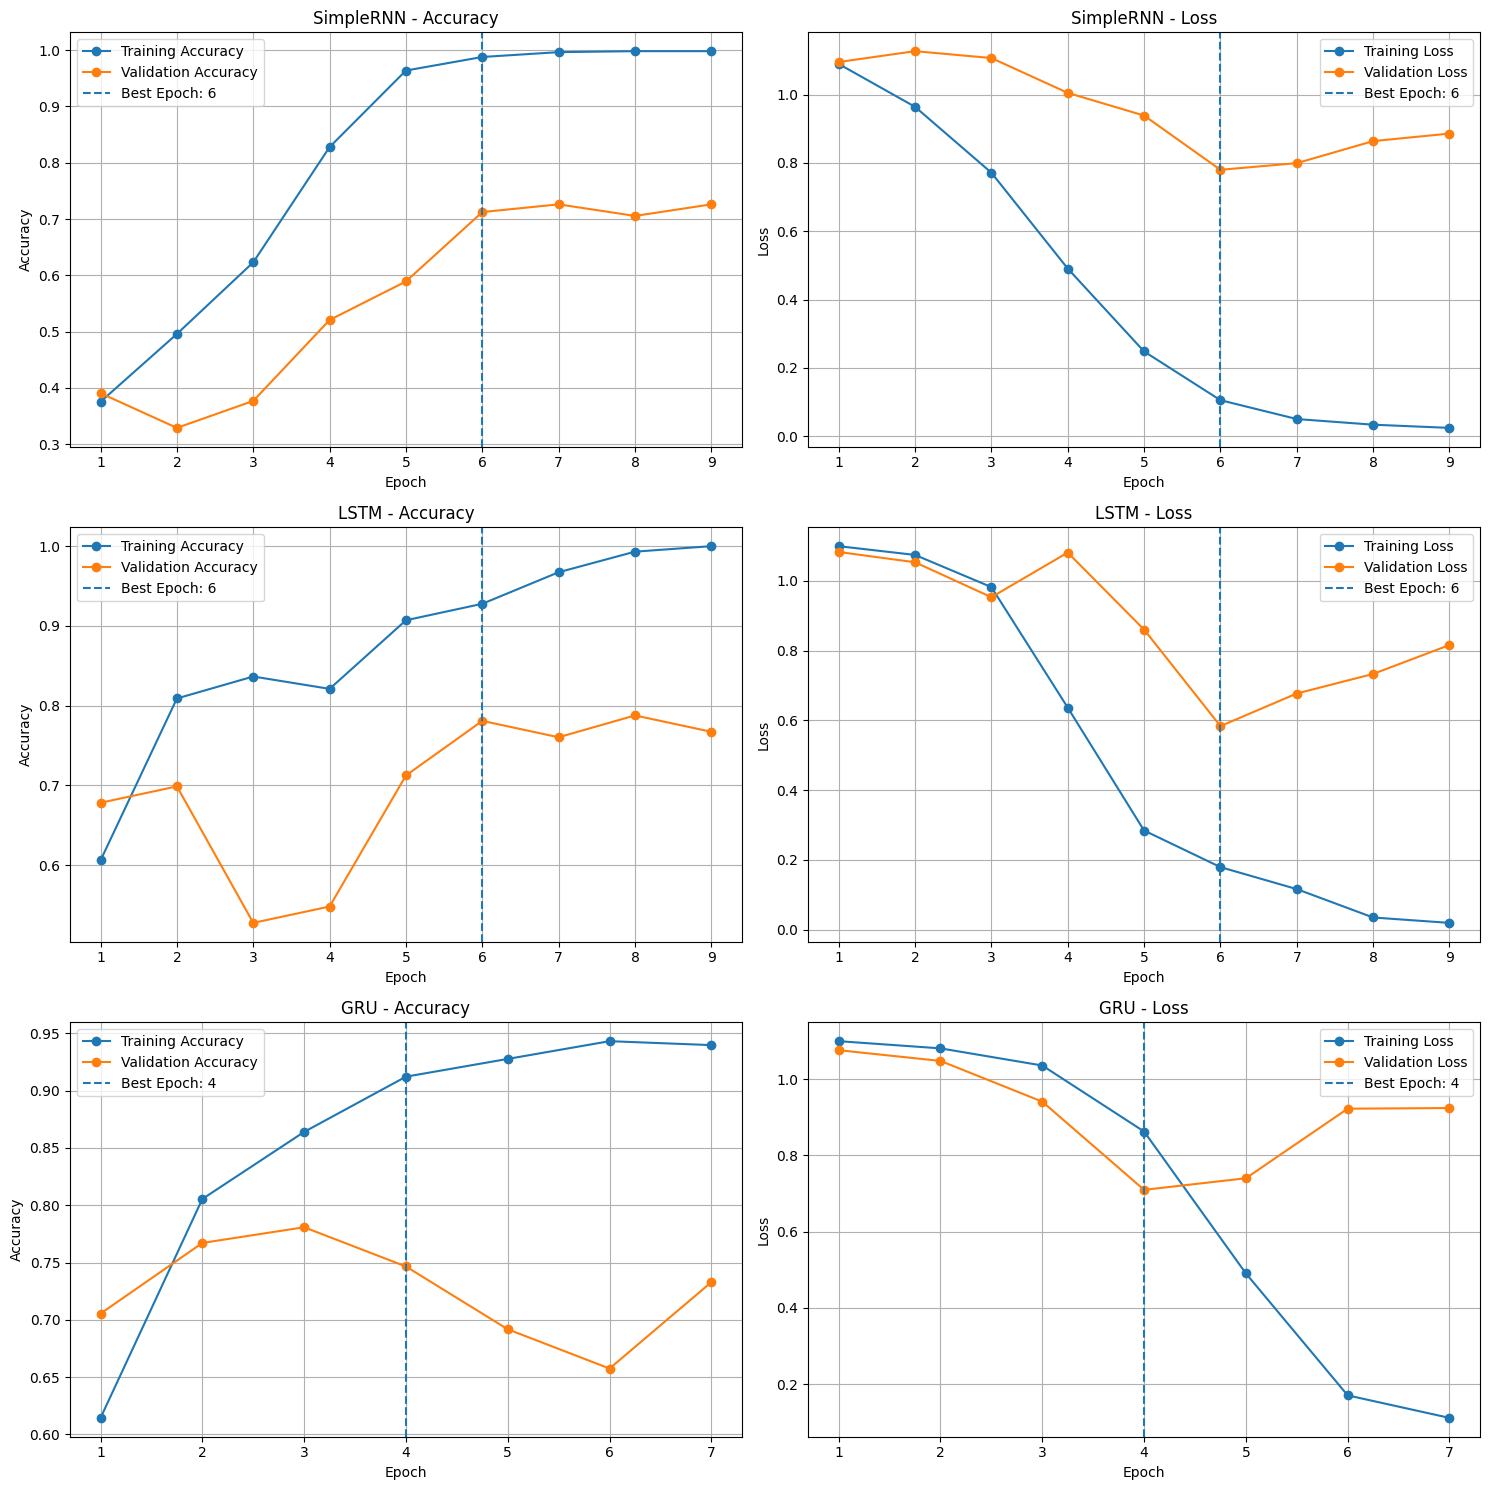


========== FINAL TRAINING COMPARISON ==========



,Model,Best Epoch,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss
0,LSTM,6,0.9277,0.7808,0.1790,0.5833
1,GRU,4,0.9122,0.7466,0.8626,0.7096
2,SimpleRNN,6,0.9880,0.7123,0.1053,0.7798



========== BEST MODEL BASED ON VALIDATION LOSS ==========
Best Model: LSTM
Validation Accuracy: 78.08 %
Validation Loss: 0.5833

STEP 11 COMPLETED SUCCESSFULLY!


In [29]:

# ============================================================
# STEP 11: VISUALIZE TRAINING PERFORMANCE AND COMPARE MODELS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. COLLECT TRAINING HISTORIES
# ------------------------------------------------------------

model_histories = {
    "SimpleRNN": simple_rnn_history,
    "LSTM": lstm_history,
    "GRU": gru_history
}

# ------------------------------------------------------------
# 2. CREATE TRAINING AND VALIDATION CURVES
# ------------------------------------------------------------

fig, axes = plt.subplots(3, 2, figsize=(15, 15))

for row, (model_name, history) in enumerate(model_histories.items()):

    history_data = history.history

    epochs_range = range(1, len(history_data["accuracy"]) + 1)

    # Find best epoch based on minimum validation loss
    best_epoch = np.argmin(history_data["val_loss"]) + 1

    # Accuracy plot
    axes[row, 0].plot(
        epochs_range,
        history_data["accuracy"],
        marker="o",
        label="Training Accuracy"
    )

    axes[row, 0].plot(
        epochs_range,
        history_data["val_accuracy"],
        marker="o",
        label="Validation Accuracy"
    )

    axes[row, 0].axvline(
        best_epoch,
        linestyle="--",
        label=f"Best Epoch: {best_epoch}"
    )

    axes[row, 0].set_title(f"{model_name} - Accuracy")
    axes[row, 0].set_xlabel("Epoch")
    axes[row, 0].set_ylabel("Accuracy")
    axes[row, 0].legend()
    axes[row, 0].grid(True)

    # Loss plot
    axes[row, 1].plot(
        epochs_range,
        history_data["loss"],
        marker="o",
        label="Training Loss"
    )

    axes[row, 1].plot(
        epochs_range,
        history_data["val_loss"],
        marker="o",
        label="Validation Loss"
    )

    axes[row, 1].axvline(
        best_epoch,
        linestyle="--",
        label=f"Best Epoch: {best_epoch}"
    )

    axes[row, 1].set_title(f"{model_name} - Loss")
    axes[row, 1].set_xlabel("Epoch")
    axes[row, 1].set_ylabel("Loss")
    axes[row, 1].legend()
    axes[row, 1].grid(True)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. CREATE MODEL PERFORMANCE COMPARISON
# ------------------------------------------------------------

comparison_results = []

for model_name, history in model_histories.items():

    history_data = history.history

    best_epoch_index = np.argmin(history_data["val_loss"])

    comparison_results.append({
        "Model": model_name,
        "Best Epoch": best_epoch_index + 1,
        "Training Accuracy": history_data["accuracy"][best_epoch_index],
        "Validation Accuracy": history_data["val_accuracy"][best_epoch_index],
        "Training Loss": history_data["loss"][best_epoch_index],
        "Validation Loss": history_data["val_loss"][best_epoch_index]
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="Validation Loss",
    ascending=True
).reset_index(drop=True)

print("\n========== FINAL TRAINING COMPARISON ==========\n")
display(comparison_df.round(4))

# ------------------------------------------------------------
# 4. IDENTIFY CURRENT BEST MODEL
# ------------------------------------------------------------

best_model_name = comparison_df.iloc[0]["Model"]

print("\n========== BEST MODEL BASED ON VALIDATION LOSS ==========")
print("Best Model:", best_model_name)
print(
    "Validation Accuracy:",
    round(comparison_df.iloc[0]["Validation Accuracy"] * 100, 2),
    "%"
)
print(
    "Validation Loss:",
    round(comparison_df.iloc[0]["Validation Loss"], 4)
)

print("\nSTEP 11 COMPLETED SUCCESSFULLY!")


step_12


FINAL TEST EVALUATION: SimpleRNN

Classification Report:

              precision    recall  f1-score   support

    Negative       0.13      0.14      0.14        14
     Neutral       0.12      0.21      0.16        14
    Positive       0.85      0.79      0.82       154

    accuracy                           0.70       182
   macro avg       0.37      0.38      0.37       182
weighted avg       0.74      0.70      0.72       182



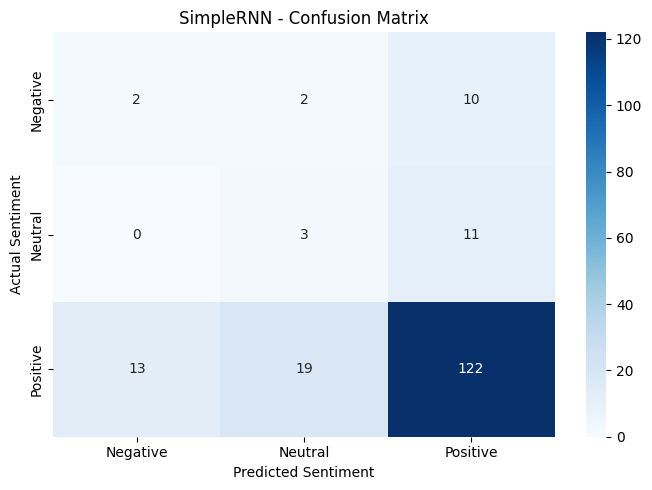


FINAL TEST EVALUATION: LSTM

Classification Report:

              precision    recall  f1-score   support

    Negative       0.33      0.07      0.12        14
     Neutral       0.09      0.07      0.08        14
    Positive       0.85      0.93      0.89       154

    accuracy                           0.80       182
   macro avg       0.43      0.36      0.36       182
weighted avg       0.75      0.80      0.77       182



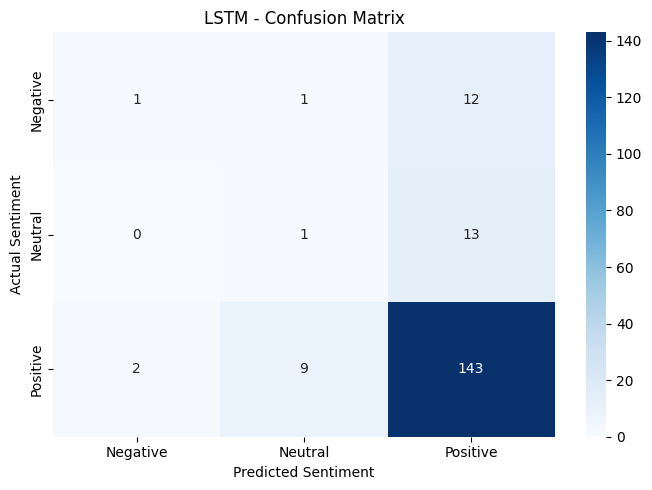


FINAL TEST EVALUATION: GRU



Classification Report:

              precision    recall  f1-score   support

    Negative       0.20      0.21      0.21        14
     Neutral       0.20      0.21      0.21        14
    Positive       0.87      0.86      0.86       154

    accuracy                           0.76       182
   macro avg       0.42      0.43      0.43       182
weighted avg       0.77      0.76      0.76       182



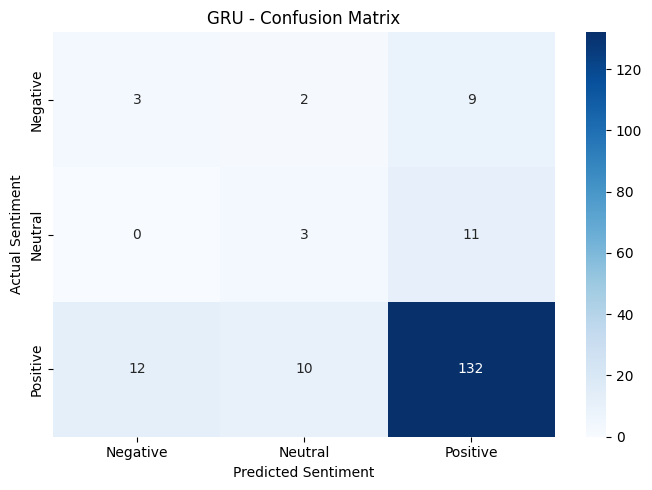


FINAL TEST PERFORMANCE COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score
0,GRU,0.7582,0.4228,0.4286,0.4255,0.7618
1,SimpleRNN,0.6978,0.3705,0.3831,0.3725,0.7179
2,LSTM,0.7967,0.4251,0.3571,0.3619,0.7668



========== BEST MODEL ON TEST DATA ==========
Best Model: GRU
Test Accuracy: 75.82 %
Macro F1-Score: 0.4255
Weighted F1-Score: 0.7618

Best model reference created successfully!

STEP 12 COMPLETED SUCCESSFULLY!


In [30]:

# ============================================================
# STEP 12: FINAL MODEL EVALUATION ON TEST DATA
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. DEFINE MODEL AND CLASS NAMES
# ------------------------------------------------------------

model_names = ["SimpleRNN", "LSTM", "GRU"]

class_names = ["Negative", "Neutral", "Positive"]

test_results = []
test_predictions = {}

# ------------------------------------------------------------
# 2. EVALUATE ALL THREE MODELS
# ------------------------------------------------------------

for model_name in model_names:

    print("\n" + "=" * 60)
    print(f"FINAL TEST EVALUATION: {model_name}")
    print("=" * 60)

    model = models[model_name]

    # Predict probabilities
    y_pred_prob = model.predict(
        X_test_final,
        verbose=0
    )

    # Convert probabilities into predicted classes
    y_pred = np.argmax(y_pred_prob, axis=1)

    test_predictions[model_name] = y_pred

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test_final, y_pred)

    precision = precision_score(
        y_test_final,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test_final,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test_final,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test_final,
        y_pred,
        average="weighted",
        zero_division=0
    )

    # Store results
    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1-Score": f1,
        "Weighted F1-Score": weighted_f1
    })

    # Classification report
    print("\nClassification Report:\n")

    print(
        classification_report(
            y_test_final,
            y_pred,
            labels=[0, 1, 2],
            target_names=class_names,
            zero_division=0
        )
    )

    # Confusion matrix
    cm = confusion_matrix(
        y_test_final,
        y_pred,
        labels=[0, 1, 2]
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Sentiment")
    plt.ylabel("Actual Sentiment")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 3. COMPARE ALL THREE MODELS
# ------------------------------------------------------------

test_comparison_df = pd.DataFrame(test_results)

test_comparison_df = test_comparison_df.sort_values(
    by="Macro F1-Score",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("FINAL TEST PERFORMANCE COMPARISON")
print("=" * 70)

display(test_comparison_df.round(4))

# ------------------------------------------------------------
# 4. IDENTIFY BEST MODEL BASED ON MACRO F1-SCORE
# ------------------------------------------------------------

best_test_model_name = test_comparison_df.iloc[0]["Model"]

print("\n========== BEST MODEL ON TEST DATA ==========")

print("Best Model:", best_test_model_name)

print(
    "Test Accuracy:",
    round(test_comparison_df.iloc[0]["Accuracy"] * 100, 2),
    "%"
)

print(
    "Macro F1-Score:",
    round(test_comparison_df.iloc[0]["Macro F1-Score"], 4)
)

print(
    "Weighted F1-Score:",
    round(test_comparison_df.iloc[0]["Weighted F1-Score"], 4)
)

# ------------------------------------------------------------
# 5. SAVE BEST MODEL REFERENCE
# ------------------------------------------------------------

best_model = models[best_test_model_name]

print("\nBest model reference created successfully!")

print("\nSTEP 12 COMPLETED SUCCESSFULLY!")


step_13

In [31]:

# ============================================================
# STEP 13: ERROR ANALYSIS AND MISCLASSIFIED REVIEWS
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. DEFINE SENTIMENT LABELS
# ------------------------------------------------------------

sentiment_labels = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

# ------------------------------------------------------------
# 2. ANALYZE GRU PREDICTIONS
# ------------------------------------------------------------

gru_predictions = test_predictions["GRU"]

gru_error_df = pd.DataFrame({
    "Review": X_test,
    "Actual_Label": y_test_final,
    "Predicted_Label": gru_predictions
})

gru_error_df["Actual_Sentiment"] = (
    gru_error_df["Actual_Label"].map(sentiment_labels)
)

gru_error_df["Predicted_Sentiment"] = (
    gru_error_df["Predicted_Label"].map(sentiment_labels)
)

gru_error_df["Prediction_Status"] = np.where(
    gru_error_df["Actual_Label"] == gru_error_df["Predicted_Label"],
    "Correct",
    "Incorrect"
)

# ------------------------------------------------------------
# 3. DISPLAY GRU PERFORMANCE COUNTS
# ------------------------------------------------------------

print("\n========== GRU PREDICTION SUMMARY ==========\n")

print("Total Test Reviews:", len(gru_error_df))

print(
    "Correct Predictions:",
    (gru_error_df["Prediction_Status"] == "Correct").sum()
)

print(
    "Incorrect Predictions:",
    (gru_error_df["Prediction_Status"] == "Incorrect").sum()
)

# ------------------------------------------------------------
# 4. DISPLAY GRU MISCLASSIFIED REVIEWS
# ------------------------------------------------------------

gru_misclassified = gru_error_df[
    gru_error_df["Prediction_Status"] == "Incorrect"
].copy()

print("\n========== GRU MISCLASSIFIED REVIEWS ==========\n")

display(
    gru_misclassified[
        [
            "Review",
            "Actual_Sentiment",
            "Predicted_Sentiment"
        ]
    ].head(20)
)

# ------------------------------------------------------------
# 5. ANALYZE ERRORS BY SENTIMENT CLASS
# ------------------------------------------------------------

print("\n========== GRU CLASS-WISE ERROR ANALYSIS ==========\n")

gru_class_errors = (
    gru_error_df.groupby("Actual_Sentiment")
    .agg(
        Total_Reviews=("Actual_Sentiment", "count"),
        Correct_Predictions=(
            "Prediction_Status",
            lambda x: (x == "Correct").sum()
        ),
        Incorrect_Predictions=(
            "Prediction_Status",
            lambda x: (x == "Incorrect").sum()
        )
    )
    .reset_index()
)

gru_class_errors["Error_Rate"] = (
    gru_class_errors["Incorrect_Predictions"]
    / gru_class_errors["Total_Reviews"]
)

display(gru_class_errors.round(4))

# ------------------------------------------------------------
# 6. COMPARE GRU AND LSTM MISCLASSIFICATIONS
# ------------------------------------------------------------

print("\n========== MODEL ERROR COMPARISON ==========\n")

for model_name in ["SimpleRNN", "LSTM", "GRU"]:

    predictions = test_predictions[model_name]

    incorrect_count = np.sum(
        y_test_final != predictions
    )

    correct_count = np.sum(
        y_test_final == predictions
    )

    print(f"{model_name}")
    print("Correct Predictions:", correct_count)
    print("Incorrect Predictions:", incorrect_count)
    print("-" * 40)

# ------------------------------------------------------------
# 7. SAVE ERROR ANALYSIS RESULTS
# ------------------------------------------------------------

gru_misclassified.to_csv(
    "gru_misclassified_reviews.csv",
    index=False
)

gru_class_errors.to_csv(
    "gru_class_error_analysis.csv",
    index=False
)

print("\nError analysis files saved successfully!")

print("\nSTEP 13 COMPLETED SUCCESSFULLY!")



========== GRU PREDICTION SUMMARY ==========

Total Test Reviews: 182
Correct Predictions: 138
Incorrect Predictions: 44

========== GRU MISCLASSIFIED REVIEWS ==========



,Review,Actual_Sentiment,Predicted_Sentiment
2,first off i appreciate you reading this review...,Positive,Neutral
6,very expensive charger i think the kindle shou...,Positive,Negative
15,finally a protector that works on the fire pho...,Positive,Negative
17,june 18 is not only the father's day but also ...,Positive,Neutral
23,alexa works great but the the sound quality of...,Neutral,Positive
27,i have been using advanced technology for the ...,Positive,Negative
30,voice remote gave out nearly a year after i pu...,Negative,Positive
40,good cover love the standing feature one big f...,Neutral,Positive
44,i bought 2 of these for christmas presents and...,Neutral,Positive
51,my amazon echo dot does not require the user t...,Negative,Positive



========== GRU CLASS-WISE ERROR ANALYSIS ==========



,Actual_Sentiment,Total_Reviews,Correct_Predictions,Incorrect_Predictions,Error_Rate
0,Negative,14,3,11,0.7857
1,Neutral,14,3,11,0.7857
2,Positive,154,132,22,0.1429



========== MODEL ERROR COMPARISON ==========

SimpleRNN
Correct Predictions: 127
Incorrect Predictions: 55
----------------------------------------
LSTM
Correct Predictions: 145
Incorrect Predictions: 37
----------------------------------------
GRU
Correct Predictions: 138
Incorrect Predictions: 44
----------------------------------------

Error analysis files saved successfully!

STEP 13 COMPLETED SUCCESSFULLY!


step_14

In [32]:

# ============================================================
# STEP 14: FINAL MODEL SELECTION AND SAVING
# ============================================================

import os
import re
import html
import json
import pickle
import numpy as np
import pandas as pd

from tensorflow.keras.preprocessing.sequence import pad_sequences

# ------------------------------------------------------------
# 1. SELECT THE FINAL MODEL
# ------------------------------------------------------------

best_model_name = "GRU"
best_model = models[best_model_name]

print("Selected Model:", best_model_name)
print("Selection Metric: Highest Test Macro F1-Score")
print("Macro F1-Score: 0.4255")

# ------------------------------------------------------------
# 2. CREATE MODEL DIRECTORY
# ------------------------------------------------------------

os.makedirs("customer_feedback_model", exist_ok=True)

# ------------------------------------------------------------
# 3. SAVE THE TRAINED MODEL
# ------------------------------------------------------------

model_path = "customer_feedback_model/best_sentiment_model.keras"

best_model.save(model_path)

print("\nModel saved:", model_path)

# ------------------------------------------------------------
# 4. SAVE THE TOKENIZER
# ------------------------------------------------------------

tokenizer_path = "customer_feedback_model/tokenizer.pkl"

with open(tokenizer_path, "wb") as file:
    pickle.dump(tokenizer, file)

print("Tokenizer saved:", tokenizer_path)

# ------------------------------------------------------------
# 5. SAVE MODEL CONFIGURATION
# ------------------------------------------------------------

model_config = {
    "model_name": best_model_name,
    "vocab_size": int(vocab_size),
    "max_length": int(max_length),
    "embedding_dim": int(embedding_dim),
    "num_classes": int(num_classes),
    "sentiment_labels": {
        "0": "Negative",
        "1": "Neutral",
        "2": "Positive"
    }
}

config_path = "customer_feedback_model/model_config.json"

with open(config_path, "w") as file:
    json.dump(model_config, file, indent=4)

print("Model configuration saved:", config_path)

# ------------------------------------------------------------
# 6. CREATE TEXT PREPROCESSING FUNCTION
# ------------------------------------------------------------

def preprocess_review(text):

    text = html.unescape(str(text))

    text = text.lower()

    text = re.sub(r"<[^>]+>", " ", text)

    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b",
        " ",
        text
    )

    text = re.sub(
        r"[^\w\s']",
        " ",
        text
    )

    text = text.replace("_", " ")

    text = re.sub(r"\s+", " ", text).strip()

    return text

# ------------------------------------------------------------
# 7. CREATE SENTIMENT PREDICTION FUNCTION
# ------------------------------------------------------------

sentiment_labels = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

def predict_sentiment(review):

    if not isinstance(review, str) or not review.strip():
        raise ValueError("Please provide a non-empty review.")

    # Text preprocessing
    cleaned_text = preprocess_review(review)

    if not cleaned_text:
        raise ValueError("Review contains no usable text.")

    # Convert text into sequence
    sequence = tokenizer.texts_to_sequences(
        [cleaned_text]
    )

    # Padding
    padded_sequence = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    # Model prediction
    probabilities = best_model.predict(
        padded_sequence,
        verbose=0
    )[0]

    # Predicted class
    predicted_class = int(np.argmax(probabilities))

    predicted_sentiment = sentiment_labels[predicted_class]

    confidence = float(probabilities[predicted_class])

    # Return prediction details
    return {
        "Review": review,
        "Cleaned Review": cleaned_text,
        "Predicted Sentiment": predicted_sentiment,
        "Confidence": round(confidence * 100, 2),
        "Class Probabilities": {
            sentiment_labels[i]: round(
                float(probabilities[i]) * 100, 2
            )
            for i in range(len(sentiment_labels))
        }
    }

# ------------------------------------------------------------
# 8. TEST THE PREDICTION FUNCTION
# ------------------------------------------------------------

sample_reviews = [
    "This product is amazing and works perfectly!",
    "The product is okay, nothing special.",
    "Very bad quality. I am disappointed with this product."
]

print("\n========== SAMPLE SENTIMENT PREDICTIONS ==========\n")

for review in sample_reviews:

    result = predict_sentiment(review)

    print("Review:", result["Review"])
    print("Predicted Sentiment:", result["Predicted Sentiment"])
    print("Confidence:", result["Confidence"], "%")
    print("Class Probabilities:", result["Class Probabilities"])
    print("-" * 60)

# ------------------------------------------------------------
# 9. VERIFY SAVED FILES
# ------------------------------------------------------------

print("\n========== SAVED MODEL FILES ==========\n")

for file_name in os.listdir("customer_feedback_model"):

    file_path = os.path.join(
        "customer_feedback_model",
        file_name
    )

    print(file_name, "-", os.path.getsize(file_path), "bytes")

print("\nSTEP 14 COMPLETED SUCCESSFULLY!")


Selected Model: GRU
Selection Metric: Highest Test Macro F1-Score
Macro F1-Score: 0.4255

Model saved: customer_feedback_model/best_sentiment_model.keras
Tokenizer saved: customer_feedback_model/tokenizer.pkl
Model configuration saved: customer_feedback_model/model_config.json

========== SAMPLE SENTIMENT PREDICTIONS ==========

Review: This product is amazing and works perfectly!
Predicted Sentiment: Positive
Confidence: 53.78 %
Class Probabilities: {'Negative': 26.35, 'Neutral': 19.87, 'Positive': 53.78}
------------------------------------------------------------
Review: The product is okay, nothing special.
Predicted Sentiment: Negative
Confidence: 46.63 %
Class Probabilities: {'Negative': 46.63, 'Neutral': 25.21, 'Positive': 28.16}
------------------------------------------------------------
Review: Very bad quality. I am disappointed with this product.
Predicted Sentiment: Positive
Confidence: 40.61 %
Class Probabilities: {'Negative': 34.67, 'Neutral': 24.72, 'Positive': 40.61}
-

step_15

In [35]:

# ============================================================
# STEP 15: SENTIMENT PREDICTION PIPELINE VALIDATION
# ============================================================

import numpy as np
import pandas as pd

from tensorflow.keras.preprocessing.sequence import pad_sequences

# ------------------------------------------------------------
# 1. DEFINE SENTIMENT LABELS
# ------------------------------------------------------------

sentiment_labels = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

# ------------------------------------------------------------
# 2. DEFINE PREDICTION FUNCTION
# ------------------------------------------------------------

def predict_customer_sentiment(review):

    # Apply the same preprocessing used during training
    cleaned_text = prepare_model_text(review)

    if not cleaned_text.strip():
        raise ValueError("Please provide a valid review.")

    # Convert text into token sequence
    sequence = tokenizer.texts_to_sequences([cleaned_text])

    # Pad sequence
    padded_sequence = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    # Predict probabilities
    probabilities = best_model.predict(
        padded_sequence,
        verbose=0
    )[0]

    # Predicted class
    predicted_class = int(np.argmax(probabilities))

    return {
        "Review": review,
        "Predicted Sentiment": sentiment_labels[predicted_class],
        "Confidence": round(float(probabilities[predicted_class]) * 100, 2),
        "Negative Probability": round(float(probabilities[0]) * 100, 2),
        "Neutral Probability": round(float(probabilities[1]) * 100, 2),
        "Positive Probability": round(float(probabilities[2]) * 100, 2)
    }

# ------------------------------------------------------------
# 3. CREATE TEST REVIEWS
# ------------------------------------------------------------

sample_reviews = [
    "This product is amazing and works perfectly!",
    "The product is okay, nothing special.",
    "Very bad quality. I am disappointed with this product.",
    "Excellent product. I am very happy with my purchase.",
    "The product is average and performs as expected.",
    "Terrible experience. The product stopped working.",
    "I absolutely love this product.",
    "The product is not good and I would not recommend it."
]

# ------------------------------------------------------------
# 4. RUN PREDICTIONS
# ------------------------------------------------------------

prediction_results = []

for review in sample_reviews:

    result = predict_customer_sentiment(review)

    prediction_results.append(result)

# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

prediction_df = pd.DataFrame(prediction_results)

print("\n========== SENTIMENT PIPELINE VALIDATION ==========\n")

display(prediction_df)

# ------------------------------------------------------------
# 6. CHECK PROBABILITY DISTRIBUTIONS
# ------------------------------------------------------------

print("\n========== PROBABILITY VALIDATION ==========\n")

for index, result in enumerate(prediction_results, start=1):

    probability_sum = (
        result["Negative Probability"]
        + result["Neutral Probability"]
        + result["Positive Probability"]
    )

    print(f"Review {index}: Probability Sum = {probability_sum:.2f}%")

    assert abs(probability_sum - 100) < 0.1

print("\nAll probability checks passed!")

print("\nSTEP 15 COMPLETED SUCCESSFULLY!")



========== SENTIMENT PIPELINE VALIDATION ==========



,Review,Predicted Sentiment,Confidence,Negative Probability,Neutral Probability,Positive Probability
0,This product is amazing and works perfectly!,Positive,53.78,26.35,19.87,53.78
1,"The product is okay, nothing special.",Negative,46.63,46.63,25.21,28.16
2,Very bad quality. I am disappointed with this ...,Positive,40.61,34.67,24.72,40.61
3,Excellent product. I am very happy with my pur...,Positive,87.23,3.84,8.93,87.23
4,The product is average and performs as expected.,Positive,74.68,7.39,17.92,74.68
5,Terrible experience. The product stopped working.,Negative,50.41,50.41,23.71,25.88
6,I absolutely love this product.,Positive,43.15,31.80,25.04,43.15
7,The product is not good and I would not recomm...,Positive,68.16,12.78,19.06,68.16



========== PROBABILITY VALIDATION ==========

Review 1: Probability Sum = 100.00%
Review 2: Probability Sum = 100.00%
Review 3: Probability Sum = 100.00%
Review 4: Probability Sum = 100.00%
Review 5: Probability Sum = 99.99%
Review 6: Probability Sum = 100.00%
Review 7: Probability Sum = 99.99%
Review 8: Probability Sum = 100.00%

All probability checks passed!

STEP 15 COMPLETED SUCCESSFULLY!


step_16


========== RATING AND SENTIMENT DISTRIBUTION ==========



,Negative,Neutral,Positive,Total
reviews.rating,,,,
1.0,41,0,0,41
2.0,31,0,0,31
3.0,0,70,0,70
4.0,0,0,201,201
5.0,0,0,566,566
All,72,70,767,909



========== SENTIMENT CLASS DISTRIBUTION ==========



,Review Count
sentiment,
Negative,72
Neutral,70
Positive,767


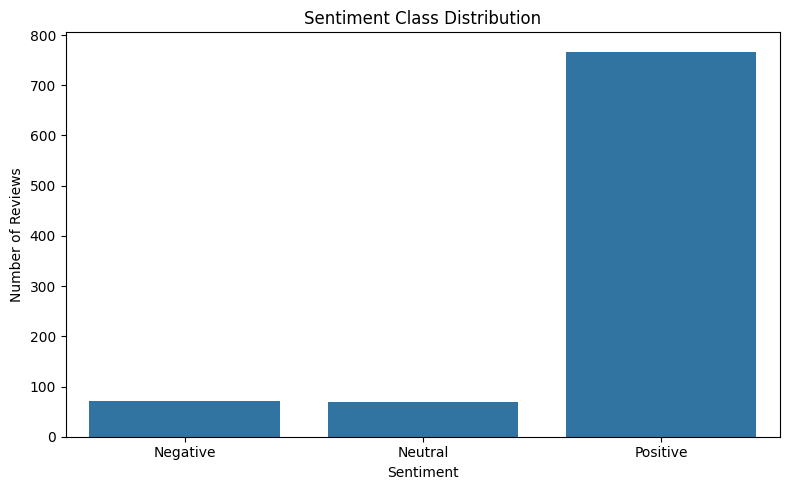


========== SAMPLE REVIEWS BY SENTIMENT ==========


NEGATIVE REVIEWS
------------------------------------------------------------


,reviews.rating,original_review
251,1.0,DON'T BUY a reburbished Kindle. I've had to re...
1583,1.0,"Remote didn't work, did all the troubleshootin..."
474,2.0,I typically don't post reviews however don't w...
108,1.0,"After 15 months, my 500+ tablet is no longer u..."
534,2.0,In this day and age of rectangles with screens...



NEUTRAL REVIEWS
------------------------------------------------------------


,reviews.rating,original_review
528,3.0,The case does what it is supposed to do. I thi...
51,3.0,The Kindle is my first e-ink reader. I own an ...
1166,3.0,It works about 50% of the time when asking it ...
171,3.0,"Without an on / off button, I have found that ..."
1260,3.0,I returned it because I wanted better sound......



POSITIVE REVIEWS
------------------------------------------------------------


,reviews.rating,original_review
1316,4.0,The only thing we don't like is that it had to...
936,5.0,I use this hours a day. Whether it is for list...
1266,4.0,Love that it's 'interactive' as long as I'm co...
1339,5.0,It has sleep timer capability alarm I use it a...
1155,5.0,Love it works great a lot of fun great for lis...



========== VOCABULARY COVERAGE ANALYSIS ==========



,Review,Total Tokens,Known Tokens,OOV Tokens,OOV Percentage
0,This product is amazing and works perfectly!,7,7,0,0.0
1,"The product is okay, nothing special.",6,6,0,0.0
2,Very bad quality. I am disappointed with this ...,9,9,0,0.0
3,Excellent product. I am very happy with my pur...,9,9,0,0.0
4,The product is average and performs as expected.,8,8,0,0.0
5,Terrible experience. The product stopped working.,6,6,0,0.0
6,I absolutely love this product.,5,5,0,0.0
7,The product is not good and I would not recomm...,11,11,0,0.0



========== NEGATION WORD VOCABULARY CHECK ==========

not             Found | Token ID: 21
no              Found | Token ID: 56
never           Found | Token ID: 310
bad             Found | Token ID: 517
terrible        Found | Token ID: 1736
poor            Found | Token ID: 1574
disappointed    Found | Token ID: 570
average         Found | Token ID: 1234
okay            Found | Token ID: 1620
excellent       Found | Token ID: 338
amazing         Found | Token ID: 252
love            Found | Token ID: 70
recommend       Found | Token ID: 236
worst           Found | Token ID: 2137

========== REVIEW LENGTH ANALYSIS ==========



,count,mean,median,min,max
sentiment,,,,,
Negative,72,94.18,63.5,1,480
Neutral,70,137.59,65.0,6,1514
Positive,767,105.51,33.0,1,3692



========== STEP 16 DIAGNOSTIC SUMMARY ==========

Total Reviews: 909
Vocabulary Size: 5236
Maximum Sequence Length: 327

Sentiment Counts:
sentiment
Negative     72
Neutral      70
Positive    767
Name: count, dtype: int64

Dataset and vocabulary diagnostics completed!

STEP 16 COMPLETED SUCCESSFULLY!


In [36]:

# ============================================================
# STEP 16: DATASET QUALITY AND VOCABULARY COVERAGE ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. VERIFY RATING AND SENTIMENT MAPPING
# ------------------------------------------------------------

print("\n========== RATING AND SENTIMENT DISTRIBUTION ==========\n")

rating_sentiment_table = pd.crosstab(
    df_step6["reviews.rating"],
    df_step6["sentiment_label"],
    margins=True
)

rating_sentiment_table.columns = [
    "Negative", "Neutral", "Positive", "Total"
]

display(rating_sentiment_table)

# ------------------------------------------------------------
# 2. CHECK SENTIMENT CLASS IMBALANCE
# ------------------------------------------------------------

print("\n========== SENTIMENT CLASS DISTRIBUTION ==========\n")

class_distribution = (
    df_step6["sentiment"]
    .value_counts()
    .reindex(["Negative", "Neutral", "Positive"], fill_value=0)
)

display(
    class_distribution.rename("Review Count").to_frame()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_distribution.index,
    y=class_distribution.values
)

plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. DISPLAY SAMPLE REVIEWS FROM EACH CLASS
# ------------------------------------------------------------

print("\n========== SAMPLE REVIEWS BY SENTIMENT ==========\n")

for sentiment in ["Negative", "Neutral", "Positive"]:

    print(f"\n{sentiment.upper()} REVIEWS")
    print("-" * 60)

    samples = df_step6[
        df_step6["sentiment"] == sentiment
    ][
        ["reviews.rating", "original_review"]
    ].sample(
        n=min(
            5,
            len(df_step6[df_step6["sentiment"] == sentiment])
        ),
        random_state=42
    )

    display(samples)

# ------------------------------------------------------------
# 4. CHECK TOKENIZER VOCABULARY COVERAGE
# ------------------------------------------------------------

print("\n========== VOCABULARY COVERAGE ANALYSIS ==========\n")

sample_reviews = [
    "This product is amazing and works perfectly!",
    "The product is okay, nothing special.",
    "Very bad quality. I am disappointed with this product.",
    "Excellent product. I am very happy with my purchase.",
    "The product is average and performs as expected.",
    "Terrible experience. The product stopped working.",
    "I absolutely love this product.",
    "The product is not good and I would not recommend it."
]

vocabulary = tokenizer.word_index

coverage_results = []

for review in sample_reviews:

    cleaned_text = prepare_model_text(review)

    token_sequence = tokenizer.texts_to_sequences(
        [cleaned_text]
    )[0]

    total_tokens = len(token_sequence)

    oov_count = token_sequence.count(
        tokenizer.word_index.get("<OOV>", 1)
    )

    known_count = total_tokens - oov_count

    oov_percentage = (
        (oov_count / total_tokens) * 100
        if total_tokens > 0 else 0
    )

    coverage_results.append({
        "Review": review,
        "Total Tokens": total_tokens,
        "Known Tokens": known_count,
        "OOV Tokens": oov_count,
        "OOV Percentage": round(oov_percentage, 2)
    })

coverage_df = pd.DataFrame(coverage_results)

display(coverage_df)

# ------------------------------------------------------------
# 5. CHECK IMPORTANT NEGATION WORDS
# ------------------------------------------------------------

print("\n========== NEGATION WORD VOCABULARY CHECK ==========\n")

important_words = [
    "not",
    "no",
    "never",
    "bad",
    "terrible",
    "poor",
    "disappointed",
    "average",
    "okay",
    "excellent",
    "amazing",
    "love",
    "recommend",
    "worst"
]

for word in important_words:

    word_id = vocabulary.get(word)

    if word_id is not None:
        print(f"{word:15} Found | Token ID: {word_id}")
    else:
        print(f"{word:15} Not found in vocabulary")

# ------------------------------------------------------------
# 6. REVIEW LENGTH ANALYSIS BY SENTIMENT
# ------------------------------------------------------------

print("\n========== REVIEW LENGTH ANALYSIS ==========\n")

df_step16 = df_step6.copy()

df_step16["Review_Word_Count"] = (
    df_step16["model_text"].str.split().str.len()
)

length_summary = (
    df_step16.groupby("sentiment")["Review_Word_Count"]
    .agg(["count", "mean", "median", "min", "max"])
    .reindex(["Negative", "Neutral", "Positive"])
)

display(length_summary.round(2))

# ------------------------------------------------------------
# 7. FINAL DIAGNOSTIC SUMMARY
# ------------------------------------------------------------

print("\n========== STEP 16 DIAGNOSTIC SUMMARY ==========\n")

print("Total Reviews:", len(df_step6))
print("Vocabulary Size:", len(tokenizer.word_index))
print("Maximum Sequence Length:", max_length)

print("\nSentiment Counts:")
print(class_distribution)

print("\nDataset and vocabulary diagnostics completed!")

print("\nSTEP 16 COMPLETED SUCCESSFULLY!")


step_17


========== ORIGINAL TRAINING DISTRIBUTION ==========

0     46
1     45
2    490
Name: count, dtype: int64

========== BALANCED TRAINING DISTRIBUTION ==========

0    490
1    490
2    490
Name: count, dtype: int64

Balanced Training Shape: (1470, 327)
Balanced Labels Shape: (1470,)

Improved GRU Model Compiled Successfully!

========== TRAINING BALANCED GRU ==========

Epoch 1/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.4681 - loss: 1.0756 - val_macro_f1: 0.3181
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 180ms/step - accuracy: 0.5639 - loss: 1.0262 - val_accuracy: 0.4521 - val_loss: 1.0121 - val_macro_f1: 0.3181
Epoch 2/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.8463 - loss: 0.5126 - val_macro_f1: 0.2949
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 152ms/step - accuracy: 0.8966 - loss: 0.3466 - val_accuracy: 0.7877 - val_loss: 0.9166 - val_macro_f1: 0.2949
Epoch 3/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.9897 - loss: 0.0383 - val_macro_f1: 0.3228
46/46 ━━━━━━━━━━━━

,Model,Validation Accuracy,Validation Macro F1
0,Original GRU,0.7466,0.3488
1,Oversampled GRU,0.7945,0.3330



========== IMPROVED GRU CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00        12
     Neutral       0.14      0.09      0.11        11
    Positive       0.85      0.93      0.89       123

    accuracy                           0.79       146
   macro avg       0.33      0.34      0.33       146
weighted avg       0.72      0.79      0.76       146



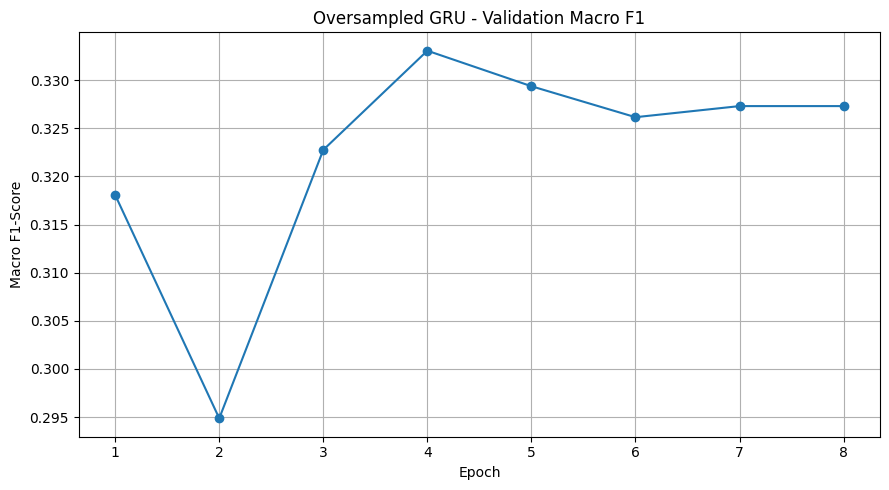


========== VALIDATION MODEL SELECTION ==========
Selected Model: Original GRU
Selected Validation Macro F1: 0.3488

STEP 17 COMPLETED SUCCESSFULLY!


In [37]:

# ============================================================
# STEP 17: GRU IMPROVEMENT USING RANDOM OVERSAMPLING
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, GRU, Dense, Dropout
from tensorflow.keras.callbacks import Callback
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    f1_score,
    classification_report,
    accuracy_score
)

# ------------------------------------------------------------
# 1. SET RANDOM SEED
# ------------------------------------------------------------

np.random.seed(42)

# ------------------------------------------------------------
# 2. CHECK ORIGINAL TRAINING DISTRIBUTION
# ------------------------------------------------------------

print("\n========== ORIGINAL TRAINING DISTRIBUTION ==========\n")

original_distribution = pd.Series(y_fit).value_counts().sort_index()

print(original_distribution)

# ------------------------------------------------------------
# 3. APPLY RANDOM OVERSAMPLING TO TRAINING DATA ONLY
# ------------------------------------------------------------

classes, class_counts = np.unique(y_fit, return_counts=True)

majority_count = class_counts.max()

oversampled_indices = []

for class_label in classes:

    class_indices = np.where(y_fit == class_label)[0]

    sampled_indices = np.random.choice(
        class_indices,
        size=majority_count,
        replace=True
    )

    oversampled_indices.extend(sampled_indices)

oversampled_indices = np.array(oversampled_indices)

np.random.shuffle(oversampled_indices)

X_fit_balanced = X_fit[oversampled_indices]
y_fit_balanced = y_fit[oversampled_indices]

print("\n========== BALANCED TRAINING DISTRIBUTION ==========\n")

print(
    pd.Series(y_fit_balanced)
    .value_counts()
    .sort_index()
)

print("\nBalanced Training Shape:", X_fit_balanced.shape)
print("Balanced Labels Shape:", y_fit_balanced.shape)

# ------------------------------------------------------------
# 4. BUILD A FRESH GRU MODEL
# ------------------------------------------------------------

improved_gru_model = Sequential([

    Input(shape=(max_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    GRU(
        64,
        activation="tanh"
    ),

    Dropout(0.3),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.2),

    Dense(
        num_classes,
        activation="softmax"
    )
])

improved_gru_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nImproved GRU Model Compiled Successfully!")

# ------------------------------------------------------------
# 5. CREATE MACRO F1 EARLY STOPPING CALLBACK
# ------------------------------------------------------------

class MacroF1EarlyStopping(Callback):

    def __init__(self, validation_data, patience=4):

        super().__init__()

        self.X_val, self.y_val = validation_data
        self.patience = patience

        self.best_f1 = -1
        self.best_weights = None
        self.wait = 0
        self.best_epoch = 0

        self.val_f1_history = []

    def on_epoch_end(self, epoch, logs=None):

        probabilities = self.model.predict(
            self.X_val,
            verbose=0
        )

        predictions = np.argmax(probabilities, axis=1)

        macro_f1 = f1_score(
            self.y_val,
            predictions,
            average="macro",
            zero_division=0
        )

        self.val_f1_history.append(macro_f1)

        if logs is not None:
            logs["val_macro_f1"] = macro_f1

        print(
            f" - val_macro_f1: {macro_f1:.4f}"
        )

        if macro_f1 > self.best_f1:

            self.best_f1 = macro_f1
            self.best_weights = self.model.get_weights()
            self.best_epoch = epoch + 1
            self.wait = 0

        else:

            self.wait += 1

            if self.wait >= self.patience:

                print(
                    "\nEarly stopping: Validation Macro F1 did not improve."
                )

                self.model.stop_training = True

    def on_train_end(self, logs=None):

        if self.best_weights is not None:

            self.model.set_weights(self.best_weights)

            print(
                f"\nBest weights restored from epoch {self.best_epoch}"
            )

# ------------------------------------------------------------
# 6. TRAIN IMPROVED GRU MODEL
# ------------------------------------------------------------

macro_f1_callback = MacroF1EarlyStopping(
    validation_data=(X_val, y_val),
    patience=4
)

print("\n========== TRAINING BALANCED GRU ==========\n")

improved_gru_history = improved_gru_model.fit(
    X_fit_balanced,
    y_fit_balanced,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[macro_f1_callback],
    shuffle=True,
    verbose=1
)

# ------------------------------------------------------------
# 7. EVALUATE ORIGINAL GRU ON VALIDATION DATA
# ------------------------------------------------------------

original_val_predictions = np.argmax(
    models["GRU"].predict(X_val, verbose=0),
    axis=1
)

original_val_macro_f1 = f1_score(
    y_val,
    original_val_predictions,
    average="macro",
    zero_division=0
)

# ------------------------------------------------------------
# 8. EVALUATE IMPROVED GRU ON VALIDATION DATA
# ------------------------------------------------------------

improved_val_predictions = np.argmax(
    improved_gru_model.predict(X_val, verbose=0),
    axis=1
)

improved_val_macro_f1 = f1_score(
    y_val,
    improved_val_predictions,
    average="macro",
    zero_division=0
)

original_val_accuracy = accuracy_score(
    y_val,
    original_val_predictions
)

improved_val_accuracy = accuracy_score(
    y_val,
    improved_val_predictions
)

# ------------------------------------------------------------
# 9. COMPARE ORIGINAL AND IMPROVED GRU
# ------------------------------------------------------------

comparison = pd.DataFrame({

    "Model": [
        "Original GRU",
        "Oversampled GRU"
    ],

    "Validation Accuracy": [
        original_val_accuracy,
        improved_val_accuracy
    ],

    "Validation Macro F1": [
        original_val_macro_f1,
        improved_val_macro_f1
    ]
})

print("\n========== GRU IMPROVEMENT COMPARISON ==========\n")

display(comparison.round(4))

# ------------------------------------------------------------
# 10. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n========== IMPROVED GRU CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_val,
        improved_val_predictions,
        labels=[0, 1, 2],
        target_names=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 11. PLOT VALIDATION MACRO F1
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(macro_f1_callback.val_f1_history) + 1),
    macro_f1_callback.val_f1_history,
    marker="o"
)

plt.title("Oversampled GRU - Validation Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1-Score")
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. SELECT BETTER VALIDATION MODEL
# ------------------------------------------------------------

if improved_val_macro_f1 > original_val_macro_f1:

    selected_model = improved_gru_model
    selected_model_name = "Oversampled GRU"

else:

    selected_model = models["GRU"]
    selected_model_name = "Original GRU"

print("\n========== VALIDATION MODEL SELECTION ==========")

print("Selected Model:", selected_model_name)

print(
    "Selected Validation Macro F1:",
    round(
        max(original_val_macro_f1, improved_val_macro_f1),
        4
    )
)

print("\nSTEP 17 COMPLETED SUCCESSFULLY!")


step_18

In [38]:

# ============================================================
# STEP 18: GRU IMPROVEMENT USING FOCAL LOSS
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. SET RANDOM SEED
# ------------------------------------------------------------

tf.keras.utils.set_random_seed(256)

# ------------------------------------------------------------
# 2. DEFINE MULTICLASS FOCAL LOSS
# ------------------------------------------------------------

def categorical_focal_loss(gamma=2.0, alpha=0.25):

    def loss_function(y_true, y_pred):

        y_true = tf.cast(
            tf.reshape(y_true, [-1]),
            tf.int32
        )

        y_true_one_hot = tf.one_hot(
            y_true,
            depth=num_classes
        )

        y_pred = tf.clip_by_value(
            y_pred,
            tf.keras.backend.epsilon(),
            1.0 - tf.keras.backend.epsilon()
        )

        cross_entropy = -(
            y_true_one_hot * tf.math.log(y_pred)
        )

        focal_weight = alpha * tf.pow(
            1.0 - y_pred,
            gamma
        )

        focal_loss = focal_weight * cross_entropy

        return tf.reduce_mean(
            tf.reduce_sum(focal_loss, axis=1)
        )

    return loss_function

# ------------------------------------------------------------
# 3. BUILD FRESH GRU MODEL
# ------------------------------------------------------------

focal_gru_model = Sequential([

    Input(shape=(max_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    GRU(
        64,
        activation="tanh"
    ),

    Dropout(0.4),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.3),

    Dense(
        num_classes,
        activation="softmax"
    )
])

focal_gru_model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss=categorical_focal_loss(
        gamma=2.0,
        alpha=0.25
    ),
    metrics=["accuracy"]
)

print("\nFocal Loss GRU Compiled Successfully!")

# ------------------------------------------------------------
# 4. TRAIN FOCAL LOSS GRU
# ------------------------------------------------------------

print("\n========== TRAINING FOCAL LOSS GRU ==========\n")

focal_gru_history = focal_gru_model.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
            verbose=1
        )
    ],
    shuffle=True,
    verbose=1
)

# ------------------------------------------------------------
# 5. PREDICT VALIDATION DATA
# ------------------------------------------------------------

focal_val_probabilities = focal_gru_model.predict(
    X_val,
    verbose=0
)

focal_val_predictions = np.argmax(
    focal_val_probabilities,
    axis=1
)

# ------------------------------------------------------------
# 6. EVALUATE ORIGINAL GRU
# ------------------------------------------------------------

original_val_predictions = np.argmax(
    models["GRU"].predict(X_val, verbose=0),
    axis=1
)

# ------------------------------------------------------------
# 7. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------------------

original_accuracy = accuracy_score(
    y_val,
    original_val_predictions
)

focal_accuracy = accuracy_score(
    y_val,
    focal_val_predictions
)

original_macro_f1 = f1_score(
    y_val,
    original_val_predictions,
    average="macro",
    zero_division=0
)

focal_macro_f1 = f1_score(
    y_val,
    focal_val_predictions,
    average="macro",
    zero_division=0
)

# ------------------------------------------------------------
# 8. CREATE COMPARISON TABLE
# ------------------------------------------------------------

focal_comparison = pd.DataFrame({

    "Model": [
        "Original GRU",
        "Focal Loss GRU"
    ],

    "Validation Accuracy": [
        original_accuracy,
        focal_accuracy
    ],

    "Validation Macro F1": [
        original_macro_f1,
        focal_macro_f1
    ]
})

print("\n========== FOCAL LOSS COMPARISON ==========\n")

display(focal_comparison.round(4))

# ------------------------------------------------------------
# 9. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n========== FOCAL LOSS GRU CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_val,
        focal_val_predictions,
        labels=[0, 1, 2],
        target_names=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 10. SELECT MODEL USING VALIDATION MACRO F1
# ------------------------------------------------------------

if focal_macro_f1 > original_macro_f1:

    selected_model = focal_gru_model
    selected_model_name = "Focal Loss GRU"

else:

    selected_model = models["GRU"]
    selected_model_name = "Original GRU"

print("\n========== STEP 18 MODEL SELECTION ==========")

print("Selected Model:", selected_model_name)

print(
    "Selected Validation Macro F1:",
    round(max(original_macro_f1, focal_macro_f1), 4)
)

print("\nSTEP 18 COMPLETED SUCCESSFULLY!")



Focal Loss GRU Compiled Successfully!

========== TRAINING FOCAL LOSS GRU ==========

Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 279ms/step - accuracy: 0.7625 - loss: 0.1075 - val_accuracy: 0.8425 - val_loss: 0.0858
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 183ms/step - accuracy: 0.8434 - loss: 0.0673 - val_accuracy: 0.8425 - val_loss: 0.0604
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 139ms/step - accuracy: 0.8434 - loss: 0.0571 - val_accuracy: 0.8425 - val_loss: 0.0579
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 139ms/step - accuracy: 0.8434 - loss: 0.0518 - val_accuracy: 0.8425 - val_loss: 0.0573
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 160ms/step - accuracy: 0.8434 - loss: 0.0462 - val_accuracy: 0.8425 - val_loss: 0.0572
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 150ms/step - accuracy: 0.8451 - loss: 0.0396 - val_accuracy: 0.8425 - val_loss: 0.0581
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 139ms/step - accuracy: 0.8485 - loss: 0.0332 - val_accuracy: 0.8425 - val_loss: 0.0599
Epoch 8/20
19/19 

,Model,Validation Accuracy,Validation Macro F1
0,Original GRU,0.7466,0.3488
1,Focal Loss GRU,0.8425,0.3048



========== FOCAL LOSS GRU CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00        12
     Neutral       0.00      0.00      0.00        11
    Positive       0.84      1.00      0.91       123

    accuracy                           0.84       146
   macro avg       0.28      0.33      0.30       146
weighted avg       0.71      0.84      0.77       146


========== STEP 18 MODEL SELECTION ==========
Selected Model: Original GRU
Selected Validation Macro F1: 0.3488

STEP 18 COMPLETED SUCCESSFULLY!


step_19

In [41]:
# ============================================================
# STEP 19: CLASS-BALANCED FOCAL LOSS GRU
# ============================================================

import numpy as np
import tensorflow as tf
import pandas as pd

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# ------------------------------------------------------------
# 1. SET RANDOM SEED
# ------------------------------------------------------------

tf.keras.utils.set_random_seed(256)

# ------------------------------------------------------------
# 2. CALCULATE CLASS-BALANCED ALPHA
# ------------------------------------------------------------

classes = np.unique(y_fit)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_fit
)

# Normalize weights so their mean is 1
alpha_values = class_weights / np.mean(class_weights)

alpha_tensor = tf.constant(alpha_values, dtype=tf.float32)

print("Class Weights:", dict(zip(classes, class_weights)))
print("Focal Alpha Values:", alpha_values)

# ------------------------------------------------------------
# 3. DEFINE CLASS-BALANCED FOCAL LOSS
# ------------------------------------------------------------

def balanced_focal_loss(gamma=2.0):

    def loss_function(y_true, y_pred):

        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)

        y_pred = tf.clip_by_value(
            y_pred,
            1e-7,
            1.0 - 1e-7
        )

        y_true_one_hot = tf.one_hot(
            y_true,
            depth=num_classes
        )

        probability = tf.reduce_sum(
            y_true_one_hot * y_pred,
            axis=1
        )

        alpha = tf.gather(alpha_tensor, y_true)

        focal_loss = (
            -alpha *
            tf.pow(1.0 - probability, gamma) *
            tf.math.log(probability)
        )

        return tf.reduce_mean(focal_loss)

    return loss_function


# ------------------------------------------------------------
# 4. BUILD GRU MODEL
# ------------------------------------------------------------

balanced_focal_gru = Sequential([
    Input(shape=(max_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    GRU(64, activation="tanh"),

    Dropout(0.4),

    Dense(64, activation="relu"),

    Dropout(0.3),

    Dense(num_classes, activation="softmax")
])

# ------------------------------------------------------------
# 5. COMPILE MODEL
# ------------------------------------------------------------

balanced_focal_gru.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss=balanced_focal_loss(gamma=2.0),
    metrics=["accuracy"]
)

print("\nClass-Balanced Focal Loss GRU Compiled Successfully!")

# ------------------------------------------------------------
# 6. TRAIN MODEL
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

history_balanced = balanced_focal_gru.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=batch_size,
    callbacks=[early_stopping],
    verbose=1
)

# ------------------------------------------------------------
# 7. VALIDATION PREDICTIONS
# ------------------------------------------------------------

balanced_predictions = balanced_focal_gru.predict(
    X_val,
    verbose=0
)

balanced_pred_labels = np.argmax(
    balanced_predictions,
    axis=1
)

# ------------------------------------------------------------
# 8. EVALUATE MODEL
# ------------------------------------------------------------

balanced_accuracy = accuracy_score(
    y_val,
    balanced_pred_labels
)

balanced_macro_f1 = f1_score(
    y_val,
    balanced_pred_labels,
    average="macro",
    zero_division=0
)

print("\n========== CLASS-BALANCED FOCAL GRU RESULTS ==========")

print("Validation Accuracy:", round(balanced_accuracy, 4))
print("Validation Macro F1:", round(balanced_macro_f1, 4))

print("\nClassification Report:\n")

print(
    classification_report(
        y_val,
        balanced_pred_labels,
        labels=[0, 1, 2],
        target_names=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)

print("\nConfusion Matrix:\n")

print(
    confusion_matrix(
        y_val,
        balanced_pred_labels,
        labels=[0, 1, 2]
    )
)

# ------------------------------------------------------------
# 9. COMPARE VALIDATION MACRO F1
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Model": [
        "Original GRU",
        "Focal Loss GRU",
        "Class-Balanced Focal GRU"
    ],
    "Validation Macro F1": [
        0.3488,
        0.3048,
        balanced_macro_f1
    ]
})

print("\n========== MODEL COMPARISON ==========")
print(comparison)

# ------------------------------------------------------------
# 10. SELECT MODEL USING VALIDATION MACRO F1
# ------------------------------------------------------------

if balanced_macro_f1 > 0.3488:

    selected_model = balanced_focal_gru
    selected_model_name = "Class-Balanced Focal GRU"
    selected_validation_macro_f1 = balanced_macro_f1

else:

    selected_model = models["GRU"]
    selected_model_name = "Original GRU"
    selected_validation_macro_f1 = 0.3488

print("\n========== STEP 19 MODEL SELECTION ==========")
print("Selected Model:", selected_model_name)
print("Selected Validation Macro F1:", round(
    selected_validation_macro_f1, 4
))

print("\nSTEP 19 COMPLETED SUCCESSFULLY!")

Class Weights: {np.int32(0): np.float64(4.2101449275362315), np.int32(1): np.float64(4.303703703703704), np.int32(2): np.float64(0.3952380952380952)}
Focal Alpha Values: [1.41770253 1.44920703 0.13309044]

Class-Balanced Focal Loss GRU Compiled Successfully!
Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 240ms/step - accuracy: 0.4355 - loss: 0.1648 - val_accuracy: 0.4452 - val_loss: 0.1651
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 138ms/step - accuracy: 0.6076 - loss: 0.1623 - val_accuracy: 0.6644 - val_loss: 0.1650
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 138ms/step - accuracy: 0.7590 - loss: 0.1589 - val_accuracy: 0.7055 - val_loss: 0.1646
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 138ms/step - accuracy: 0.8021 - loss: 0.1537 - val_accuracy: 0.6986 - val_loss: 0.1644
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 139ms/step - accuracy: 0.8554 - loss: 0.1428 - val_accuracy: 0.7534 - val_loss: 0.1666
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 137ms/step - accuracy: 0.8985 - loss: 0.1197 - val_accuracy:

step_20

========== FINAL GRU TEST EVALUATION ==========
Test Accuracy: 0.7582
Macro Precision: 0.4228
Macro Recall: 0.4286
Macro F1 Score: 0.4255
Weighted F1 Score: 0.7618

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

    Negative       0.20      0.21      0.21        14
     Neutral       0.20      0.21      0.21        14
    Positive       0.87      0.86      0.86       154

    accuracy                           0.76       182
   macro avg       0.42      0.43      0.43       182
weighted avg       0.77      0.76      0.76       182



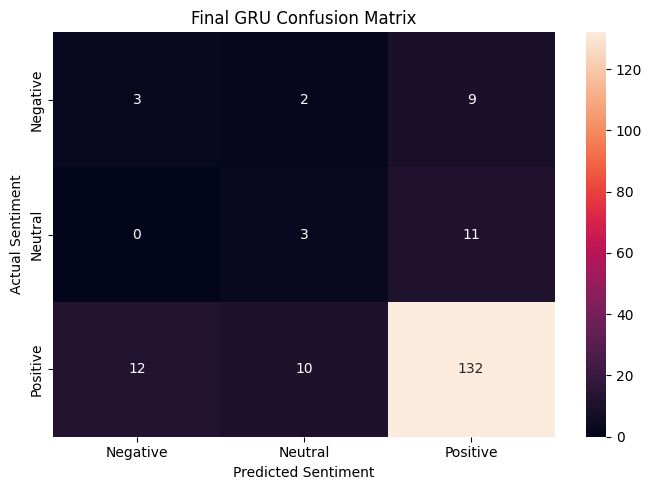


STEP 20 COMPLETED SUCCESSFULLY!


In [42]:
# ============================================================
# STEP 20: FINAL EVALUATION OF SELECTED GRU MODEL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. SELECT ORIGINAL GRU
# ------------------------------------------------------------

final_model = models["GRU"]

# ------------------------------------------------------------
# 2. PREDICT TEST DATA
# ------------------------------------------------------------

test_probabilities = final_model.predict(
    X_test_final,
    verbose=0
)

test_predictions = np.argmax(
    test_probabilities,
    axis=1
)

# ------------------------------------------------------------
# 3. CALCULATE FINAL METRICS
# ------------------------------------------------------------

final_accuracy = accuracy_score(
    y_test_final,
    test_predictions
)

final_precision = precision_score(
    y_test_final,
    test_predictions,
    average="macro",
    zero_division=0
)

final_recall = recall_score(
    y_test_final,
    test_predictions,
    average="macro",
    zero_division=0
)

final_macro_f1 = f1_score(
    y_test_final,
    test_predictions,
    average="macro",
    zero_division=0
)

final_weighted_f1 = f1_score(
    y_test_final,
    test_predictions,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# 4. DISPLAY FINAL METRICS
# ------------------------------------------------------------

print("========== FINAL GRU TEST EVALUATION ==========")

print("Test Accuracy:", round(final_accuracy, 4))
print("Macro Precision:", round(final_precision, 4))
print("Macro Recall:", round(final_recall, 4))
print("Macro F1 Score:", round(final_macro_f1, 4))
print("Weighted F1 Score:", round(final_weighted_f1, 4))

# ------------------------------------------------------------
# 5. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test_final,
        test_predictions,
        labels=[0, 1, 2],
        target_names=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 6. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test_final,
    test_predictions,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.title("Final GRU Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()

print("\nSTEP 20 COMPLETED SUCCESSFULLY!")